# Final Project Notebook - Thoracic Dataset Binary Classification
Author: Sarah Christensen

##Purpose:
To predict the outcome of survival at least up to one year post major lung surgery, using three different binary classification models and tuning and evaluating to find the best model.

###Summary:
This notebook takes the Thoracic Surgery Dataset from the UC Irvine Machine Learning Repository and validates and preprocesses for the inital exploratory analysis, then continues with the corresponding inferential statistics, and then splits the data into training and test sets for three different machine learning binary classifcation models including Logistic Regression, Support Vector Machine, and Decision Tree classifier. This notebook continues with evaluating and comparing the performance of each model, then also implements hyperparameter tuning to see if this improves any of the models' performance. The main metric for evaluating the performance of each model will be F1 score and AUC-ROC, as these models are attempting to predict survival or not and can potentially have very large impact on a patient or on their care if they were ever used in healthcare and so we would want to be wary of False Positives.





##Environment Setup
Load the following libaries and packages before running this notebook. Additional libraries may be added further into the notebook for specific chunks of code, but this will set up the necessary inital environment.
Libraries:
 - google.colab import files
 - pandas version 2.2.3
 - matplotlib.pyplot
 - seaborn version 0.13.2
 - numpy version 2.1.3
 - scipy.io import arff.

 The message "Libraries imported successfully" will print when complete.


In [1]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.io import arff

print("Libraries imported successfully.")
print(f"pandas  version: {pd.__version__}")
print(f"seaborn version: {sns.__version__}")
print(f"numpy version: {np.__version__}")

Libraries imported successfully.
pandas  version: 3.0.6
seaborn version: 0.13.2
numpy version: 2.5.4


## Data Source and Provenance
Dataset: Thoracic Surgery Data from the UC Irvine Machine Learning Repository, donated on 11/12/2013. The data comes from the Wroclaw Thoracic Surgery Centre and includes 470 patients who had major lung surgeries due to lung cancer between 2007 and 2011.  https://archive.ics.uci.edu/dataset/277/thoracic+surgery+data

Lubicz, M., Pawelczyk, K., Rzechonek, A., & Kolodziej, J. (2014). Thoracic Surgery Data [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5Z60N.

This dataset is designed for binary classification as the outcome or target variable was restricted to whether or not they survived up to one year after the lung surgery. There are 470 instances, or individual patients, and 16 features.

This dataset has the potential in learning what key variables have a high influence on the outcome, of survival one year post major lung surgery.

The initial 16 features that serve as the predictor variables in this dataset include diagnosis codes, lung capacity measurements including both Forced vital capacity (FVC) and Forced expiration volume in first second (FEV1). Also included are the performance status using the Zubrod scale, the size of the original tumor, and age at the time of the surgery. Other than the target variable of surviving the one year period post surgery, there are many other binary variables including the presence of many symptoms before surgery like, pain, coughing up blood (haemoptysis), shortness of breath (dyspnea), cough, weakness, type 2 diabetes, Myocardial Infarction (MI) up to six months, peripheral arterial disease (PAD), smoking, and asthma.

## Data Loading

Expected dataset file name: ThoraricSurgery.arff

Each of the 470 rows or instances, is an individual patient.

The target variable is:

 - Risk1Yr

where:

 - T(rue) = patient died within 1 year of lung surgery

 - F(alse) = patient survived past 1 year after lung surgery

The message "Successfully loaded: (expected dataset file name)" will print, along with the numbers of rows and columns, and the first five rows of the dataframe to verify everything was loaded and read correctly.

In [2]:
# A few additional libraries needed for loading a zipfile, unzipping and extracting the contents, which includes an .arff file.

import io
from io import StringIO
from pathlib import Path
import zipfile

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one data file.")

filename = next(iter(uploaded))
extension = Path(filename).suffix.lower()
file_data = io.BytesIO(uploaded[filename])

# GenAI citation 1: used Gemma 4 31b to figure out how to handle and unzip if the data comes from zip file.
if extension == ".zip":
    # Open the file and use io.BytesIO to handle the internal file streams
    with zipfile.ZipFile(filename, 'r') as z:
        # Get the first file inside the zip
        first_file_name = z.namelist()[0]

        # Read the file content into a virtual memory file (io)
        with z.open(first_file_name) as f:
            arff_file_data = io.StringIO(f.read().decode('utf-8')) # use io.StringIO() instead of io.BytesIO() to remove error with converting byte file into pandas df.
            # Now you can pass 'file_data' to a pandas dataframe or an image loader

            # load arff data
            data, meta = arff.loadarff(arff_file_data)

            # convert into dataframe
            df = pd.DataFrame(data)

            # Decode: Handle the remaining bytes-like objects (removes b'' from each value)
            for col in df.columns:
                if df[col].dtype == 'object':
                    df[col] = df[col].apply(lambda x: x.decode('utf-8') if isinstance(x, bytes) else x)


elif extension in [".csv", ".tsv", ".txt"]:
    # Automatically detect the delimiter.
    df = pd.read_csv(file_data, sep=None, engine="python")

elif extension in [".xlsx", ".xls"]:
    # Load the first worksheet.
    df = pd.read_excel(file_data)

elif extension == ".json":
    df = pd.read_json(file_data)

elif extension == ".parquet":
    df = pd.read_parquet(file_data)

else:
  raise ValueError(
      f"'{extension}' files require a different reader. "
  )

# =============================================================================
# Verify that the dataset loaded successfully.
# =============================================================================

print("=" * 60)

print(f"Successfully loaded: {first_file_name}")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

print("=" * 60)

display(df.head())

Saving thoracic+surgery+data.zip to thoracic+surgery+data (5).zip
Successfully loaded: ThoraricSurgery.arff
Rows: 470 | Columns: 17


,DGN,PRE4,PRE5,PRE6,PRE7,PRE8,PRE9,PRE10,PRE11,PRE14,PRE17,PRE19,PRE25,PRE30,PRE32,AGE,Risk1Yr
0,DGN2,2.88,2.16,PRZ1,F,F,F,T,T,OC14,F,F,F,T,F,60.0,F
1,DGN3,3.40,1.88,PRZ0,F,F,F,F,F,OC12,F,F,F,T,F,51.0,F
2,DGN3,2.76,2.08,PRZ1,F,F,F,T,F,OC11,F,F,F,T,F,59.0,F
3,DGN3,3.68,3.04,PRZ0,F,F,F,F,F,OC11,F,F,F,F,F,54.0,F
4,DGN3,2.44,0.96,PRZ2,F,T,F,T,T,OC11,F,F,F,T,F,73.0,T


### Enhancement 1:
The Data Loading code from the notebook, Dartmouth Programming_Additional Code, was adapted to also recognize zipfiles, extract and turn a file into a virtual memory file (io), and deal with byte-like objects so that each observation doesn't begin with b''. This code would still be able to be used for loading more common data types, as these were left in the code as conditionals if a zipfile or .arff file was not recognized.

## Data Exploration
Identify the different data types of each feature, as well as if there are any obvious missing values or duplicates that will need to be addressed in preprocessing.

In [3]:
print("\nMissing values:")
print(df.isna().sum())
print("\nData types:")
print(df.dtypes)
print("duplicates:", df.duplicated().sum())


Missing values:
DGN        0
PRE4       0
PRE5       0
PRE6       0
PRE7       0
PRE8       0
PRE9       0
PRE10      0
PRE11      0
PRE14      0
PRE17      0
PRE19      0
PRE25      0
PRE30      0
PRE32      0
AGE        0
Risk1Yr    0
dtype: int64

Data types:
DGN            str
PRE4       float64
PRE5       float64
PRE6           str
PRE7           str
PRE8           str
PRE9           str
PRE10          str
PRE11          str
PRE14          str
PRE17          str
PRE19          str
PRE25          str
PRE30          str
PRE32          str
AGE        float64
Risk1Yr        str
dtype: object
duplicates: 0


In [4]:
# @title Renaming Variables with more meaningful names.

col_names = {"DGN": "Diagnosis_code",
        "PRE4": "FVC",
        "PRE5": "FEV1",
        "PRE6": "Status",
        "PRE7": "Pain",
        "PRE8": "Haemoptysis",
        "PRE9": "Dyspnea",
        "PRE10": "Cough",
        "PRE11": "Weakness",
        "PRE14": "Tumor_size",
        "PRE17": "T2_diabetes",
        "PRE19": "MI",
        "PRE25": "PAD",
        "PRE30": "Smoking",
        "PRE32": "Asthma"}

df.rename(columns=col_names, inplace=True)

df.head()

,Diagnosis_code,FVC,FEV1,Status,Pain,Haemoptysis,Dyspnea,Cough,Weakness,Tumor_size,T2_diabetes,MI,PAD,Smoking,Asthma,AGE,Risk1Yr
0,DGN2,2.88,2.16,PRZ1,F,F,F,T,T,OC14,F,F,F,T,F,60.0,F
1,DGN3,3.40,1.88,PRZ0,F,F,F,F,F,OC12,F,F,F,T,F,51.0,F
2,DGN3,2.76,2.08,PRZ1,F,F,F,T,F,OC11,F,F,F,T,F,59.0,F
3,DGN3,3.68,3.04,PRZ0,F,F,F,F,F,OC11,F,F,F,F,F,54.0,F
4,DGN3,2.44,0.96,PRZ2,F,T,F,T,T,OC11,F,F,F,T,F,73.0,T


### Examining the Binary Target Variable
What are the counts and proportions of those who survived to one year post surgery and those who did not? About 85% of the dataset did survive while ~15% did not, indicating the dataset is unbalanced. This favors the odds of survival during the one year period post lung surgery and could bias the models, and potentially leading to false negatives, making this important to watch for. The barplot for the target variable, Risk1Yr, is included in the count barplots for all categorical variables in the next chunk of code.

In [5]:
print("Outcome counts:")
print(df["Risk1Yr"].value_counts())

print("\nOutcome proportions:")
print(df["Risk1Yr"].value_counts(normalize=True).round(3))

Outcome counts:
Risk1Yr
F    400
T     70
Name: count, dtype: int64

Outcome proportions:
Risk1Yr
F    0.851
T    0.149
Name: proportion, dtype: float64


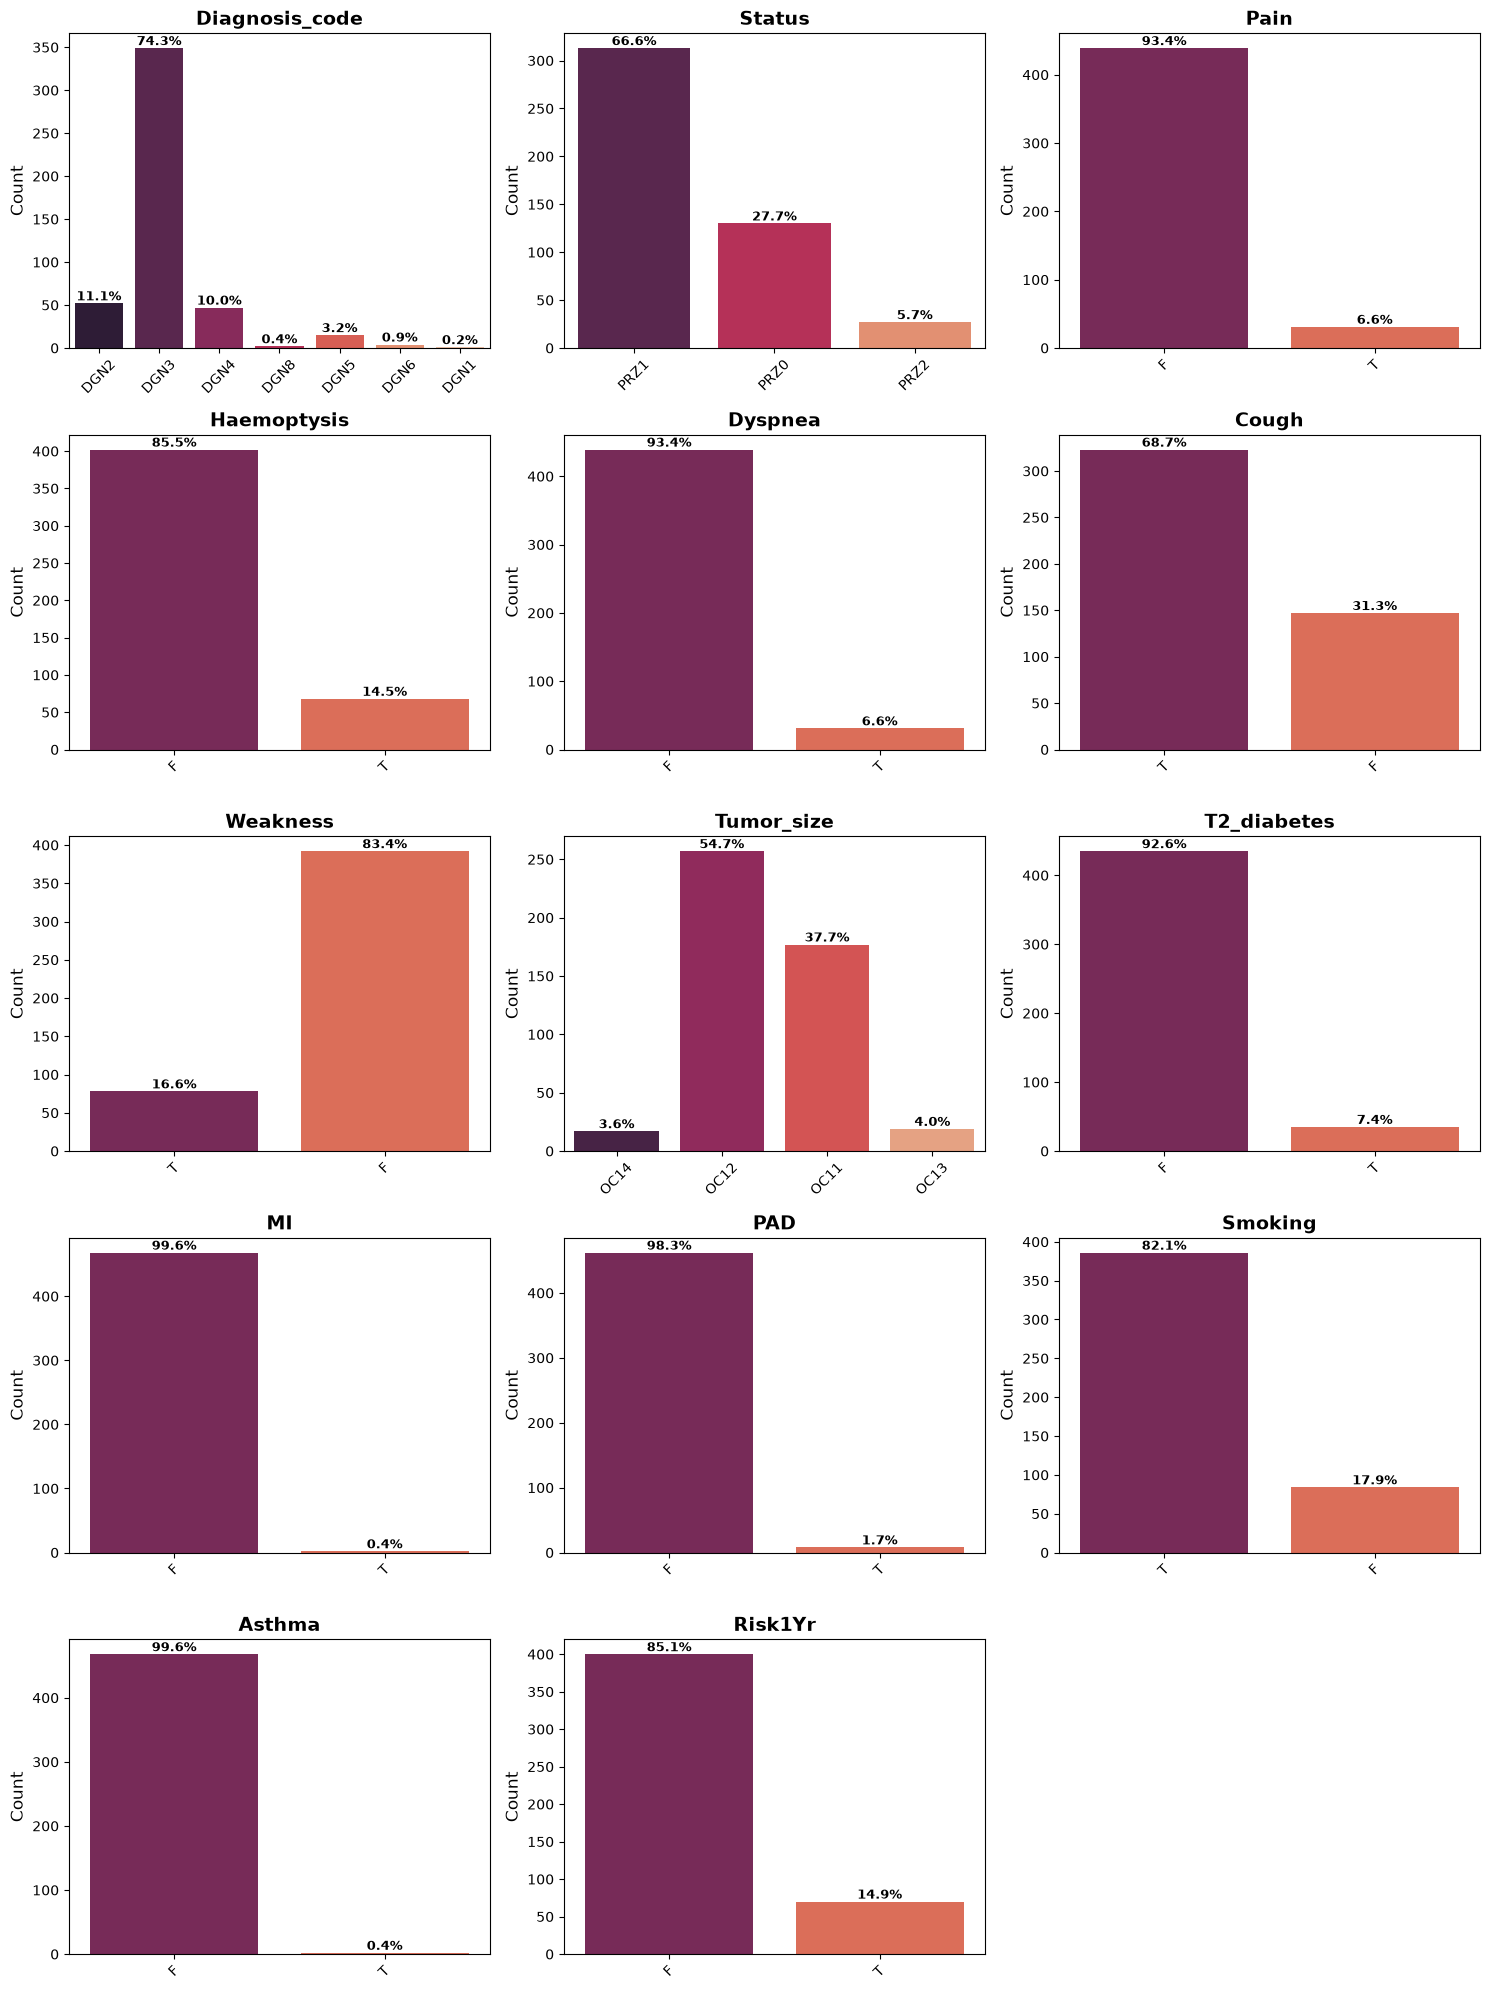

In [6]:
# @title Summarize the categorical variables

# AI citation 2. The code in this chunk was adapted using GenAI, Gemma 4 31b.

# Function to annotate bars with percentage labels
def annotate_bars(axes, series):
    total = len(series)
    for p in axes[i].patches:
        percentage = '{:.1f}%'.format(100 * p.get_height() / total)
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        axes[i].annotate(
            percentage,
            (x, y),
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold'
        )

import math

cat_columns = df.select_dtypes(include=['str']).columns.tolist()

# Define Grid Dimensions
# math.ceil rounds number to nearest integer
cols_per_row = 3
num_cols = len(cat_columns)
num_rows = math.ceil(num_cols / cols_per_row)

# Create the figure and axes
fig, axes = plt.subplots(num_rows, cols_per_row, figsize=(15, num_rows * 4))
axes = axes.flatten() # converts 2D grid of axes into 1D list

# Loop through columns and axes
for i, col in enumerate(cat_columns):
    num_categories = df[col].nunique()

    sns.countplot(
        data=df,
        x=col,
        hue=col,
        palette='rocket',
        legend=False,
        ax=axes[i]
    )

    annotate_bars(axes, df[col])

    axes[i].set_title(f'{col}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('') # Remove x-label to keep it clean
    axes[i].set_ylabel('Count', fontsize=12)
    axes[i].set_xticks(range(num_categories))
    # Rotate x-ticks if the category names are long
    axes[i].tick_params(axis='x', rotation=45)

# Clean up empty subplots
# This loop removes empty boxes.
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()



### Enhancement 2:
The function from the notebook, Dartmouth Programming_Additional Code, created for annotating the barplots with the percentages was adapted to loop through all the categorical columns to display the different count distributions for each variable, especially as many of them are unbalanced.

In [7]:
# @title Describe the continuous variables and confirm the data types

summary_num = df.describe().T

summary_num = summary_num.fillna('NA')

# Insert formatted variable name + data type
summary_num.insert(
    0,
    'Variable',
    [f"<b>{col}</b><br><span style='font-weight:normal; font-size:smaller;'>[{df[col].dtype}]</span>" for col in summary_num.index]
)

# Reset index to clean up formatting
summary_num.reset_index(drop=True, inplace=True)

# Format numeric columns to 2 decimal places only
styled_summary_num = (
    summary_num.style
    .format(precision=2, na_rep="NA")
    .set_table_styles([
        {'selector': 'th', 'props': [('font-weight', 'bold'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('text-align', 'center')]}
    ])
    .hide(axis='index')  # Remove default row index
)

styled_summary_num

Variable,count,mean,std,min,25%,50%,75%,max
FVC[float64],470.00,3.28,0.87,1.44,2.60,3.16,3.81,6.30
FEV1[float64],470.00,4.57,11.77,0.96,1.96,2.40,3.08,86.30
AGE[float64],470.00,62.53,8.71,21.00,57.00,62.00,69.00,87.00


Again, there do not appear to be any missing values in the continuous variables as the count for all three reaches 470, and there are no impossible zero values as none of the three variables have a minimum of zero. The continuous variables are correctly typed as 'float'.

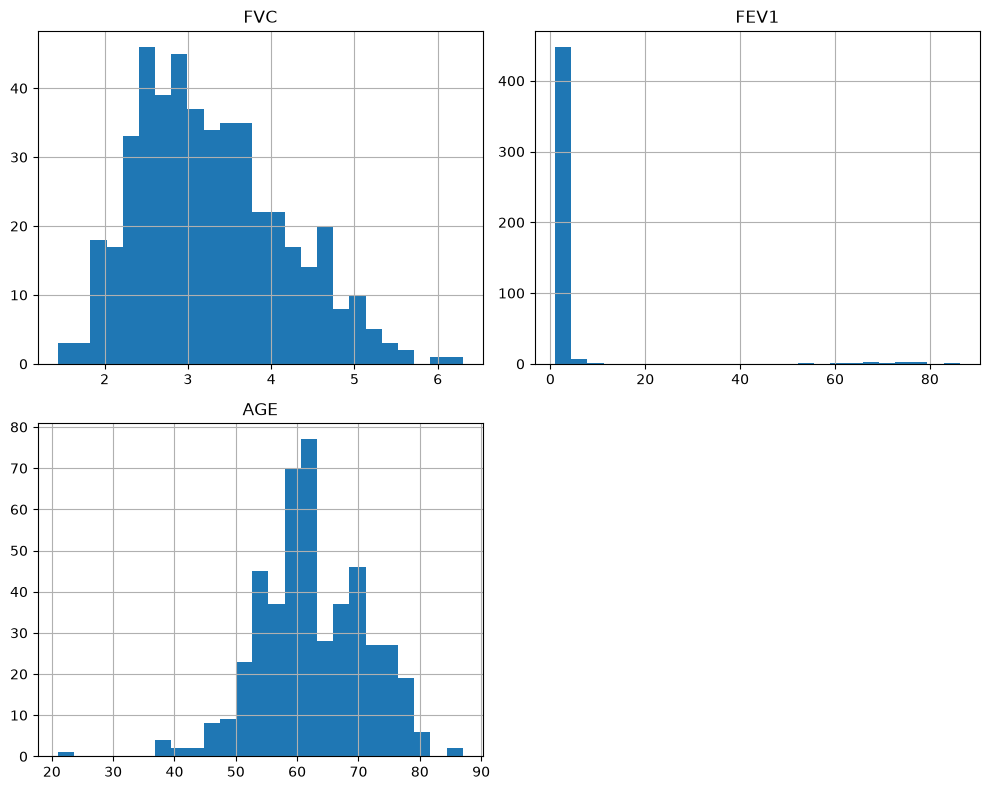

In [8]:
# @title **Generate histograms for all numerical variables**
df.hist(figsize=(10,8), bins=25)
plt.tight_layout()
plt.show()

Age and FVC could potentially be considered near normal, but do have at least a slight skewed shape. They will need to be accessed for normality before using them in inferential statistics.

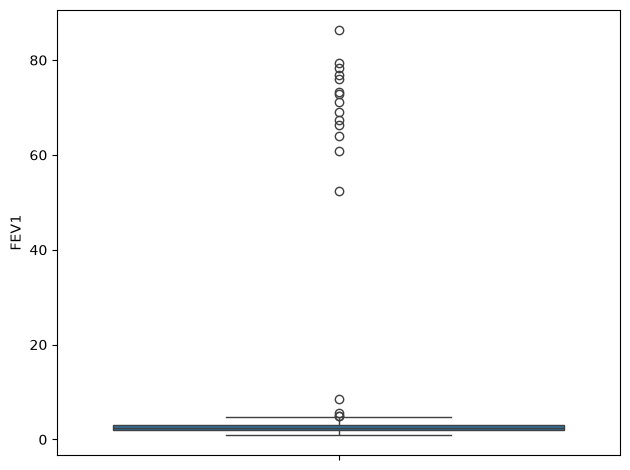

In [9]:
# @title ─────────── Boxplot of FEV1 Distribution ───────────
sns.boxplot(df['FEV1'])
plt.tight_layout()
plt.show()

The second histogram and boxplot above for the variable FEV1 indicates a large skew for this variable distribution. The histograms also show that the maximum value for the FVC variable is about 6, while the maximum value for the FEV1 variableis above 80. This does not make sense for the FEV1 value to be higher than the FVC value, so, there is likely some impossible values present in the dataset.

### Defining Lung capacity and function related variables.
Lung Capacity and function testing or Spirometry, measures the volume of air the lungs take in and then breath out at different phases. The primary measurements in this testing are Forced Vital Capacity (FVC) and Forced Expiratory Volume for 1 second (FEV1), which are both included as predictor variables in this dataset. These values are then used to calculate the FEV1/FVC ratio, as a measurement of lung function in the form of a percentage.

Understanding FVC normal range in Spirometry | spirometry.com. (n.d.). MIR. Retrieved October 16, 2026, from http://spirometry.com

Spirometry—Mayo Clinic. (n.d.). Retrieved October 16, 2026, from https://www.mayoclinic.org/tests-procedures/spirometry/about/pac-20385201



According to the American Lung Association, the estimated total lung capacity (TLC) of healthy lungs is about 6 Liters. If FVC and FEV1 are fractions of the total lung capacity, these values would likely be similar if not at least a little smaller in volume. As this estimate does not come with a description of the distribution of the population, the considered impossible values will be a conservative cut-off at 10 L, to not exclude any possible unlikely but real measurements. This cut-off will mainly address the measurements between 40 and 90 Liters for the FEV1 variable. However, this could leave some actual impossible values within the dataset, affecting the performance of the analyses and models.

Association, A. L. (n.d.). Lung Capacity and Aging. Retrieved October 16, 2026, from https://www.lung.org/lung-health-diseases/how-lungs-work/lung-capacity-and-aging

In [10]:
# @title **Identify known impossible values for later imputation**

for num in df['FEV1']:
    if num >= 10:
        df['FEV1'] = df['FEV1'].replace(num, np.nan)

print("Impossible values replaced with missing values.")
print("The ML pipeline will impute missing predictors using training data.")

Impossible values replaced with missing values.
The ML pipeline will impute missing predictors using training data.


Enhancement 3:

Recognized potientially impossible values from general knowledge of lung capacity and funciton and created a conditional statement that loops through the FEV1 variable and replaces the obviously impossible values with nan. The obviously impossible values were within the range of 40-90. There were some possible outliers below 10, but there was uncertainty if these were possible or not and so to be safe, kept them in.

In [11]:
# @title **Identify the total sum of missing values in the numeric predictors, in proportion to the non-missing values.**

target_variable = "Risk1Yr"

# Automatically identify numeric predictors.
numeric_predictors = df.select_dtypes(include="number").columns
numeric_predictors = numeric_predictors.drop(
    target_variable, errors="ignore"
)

response_counts = df[numeric_predictors].count()

# Count missing values.
missing_counts = df[numeric_predictors].isna().sum()
predictors_with_missing = missing_counts[missing_counts > 0]

df_count = pd.DataFrame({
    'Variable': response_counts.index,
    '# of Responses': response_counts.values,
    '# Missing': missing_counts.values
})

if predictors_with_missing.empty:
    print("No missing values detected in numeric predictors.")
else:
    print("Predictors requiring imputation:")
    display(df_count)

Predictors requiring imputation:


,Variable,# of Responses,# Missing
0,FVC,470,0
1,FEV1,456,14
2,AGE,470,0


The FEV1 variable is now missing 14 values with 456 total responses remaining after adding a cut-off to the range of values, thus removing values that were between 40 and 90 Liters

In [12]:
# @title Create new variable, FEV1/FVC ratio.

df['FEV1_FVC_Ratio'] = (df["FEV1"]/df["FVC"]).round(3)

df.head()

,Diagnosis_code,FVC,FEV1,Status,Pain,Haemoptysis,Dyspnea,Cough,Weakness,Tumor_size,T2_diabetes,MI,PAD,Smoking,Asthma,AGE,Risk1Yr,FEV1_FVC_Ratio
0,DGN2,2.88,2.16,PRZ1,F,F,F,T,T,OC14,F,F,F,T,F,60.0,F,0.750
1,DGN3,3.40,1.88,PRZ0,F,F,F,F,F,OC12,F,F,F,T,F,51.0,F,0.553
2,DGN3,2.76,2.08,PRZ1,F,F,F,T,F,OC11,F,F,F,T,F,59.0,F,0.754
3,DGN3,3.68,3.04,PRZ0,F,F,F,F,F,OC11,F,F,F,F,F,54.0,F,0.826
4,DGN3,2.44,0.96,PRZ2,F,T,F,T,T,OC11,F,F,F,T,F,73.0,T,0.393


Enhancement 4:

Created a new, clinically relevant, variable based on two original variables.

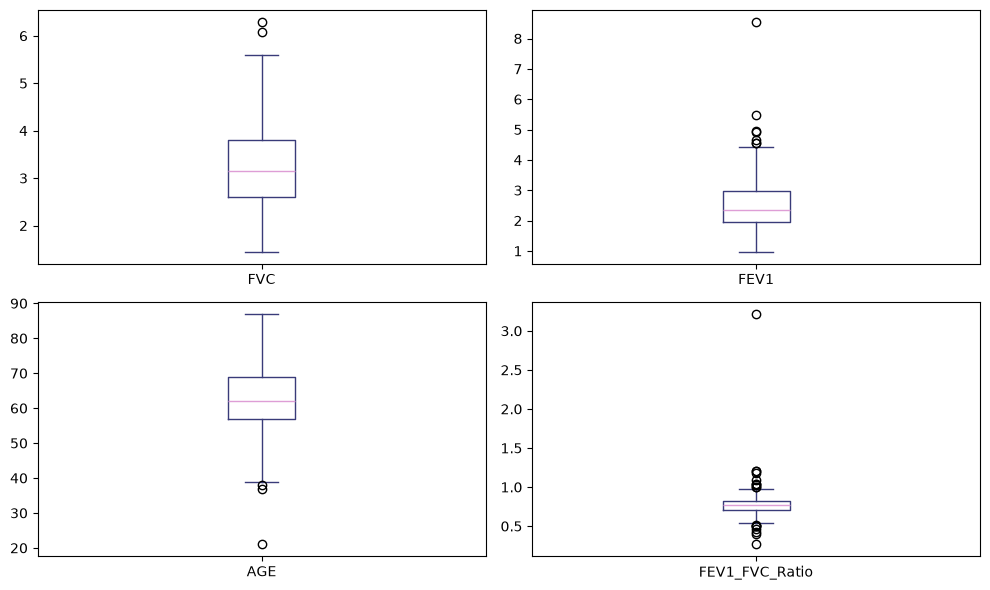

In [13]:
# @title Generate boxplots for all numerical variables.
df.plot(
    kind="box",
    subplots=True,
    layout=(2,2),
    figsize=(10,6),
    sharex=False,
    sharey=False,
    colormap='tab20b'
)

plt.tight_layout()
plt.show()

When looking at the above boxplots for the now four continuous variables, there are still a few outliers, but the FEV1 distribution does make more sense than it did, especially when displayed next to the FVC distribution.

As many of the inferential statistic methods that could be performed depend on the normality of the distribution, the below histograms provide a general overview of the distribution shapes. For the variables FVC, FEV1, and AGE, the mean is at least slightly higher than the median, indicating some degree of right-skew. The new variable of FEV1/FVC Ratio does appear more normal as the mean and median lines are right on top of each other. For plotting the detailed histograms below, the following libraries are needed: from `scipy.stats` import `norm`, and import `math`.

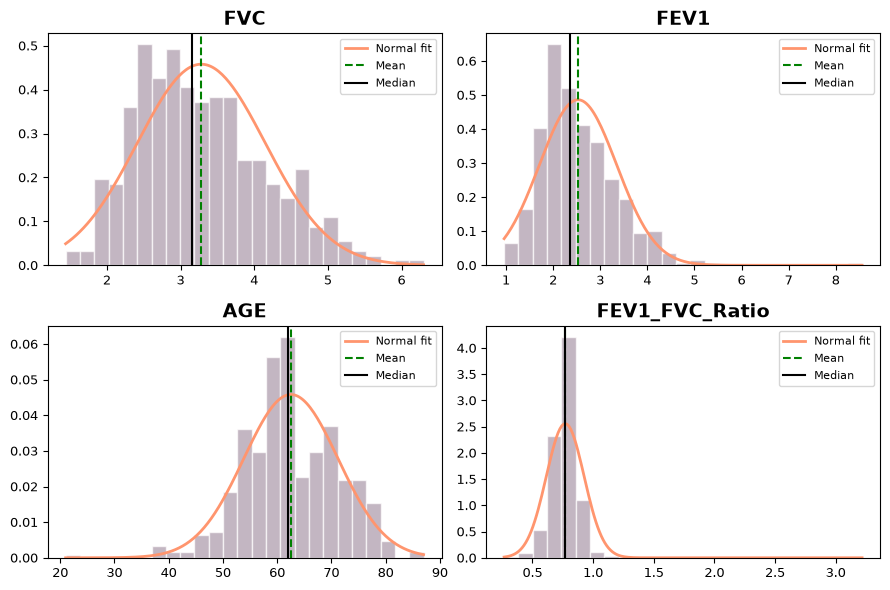

In [14]:
# @title Plot histograms to check the distribution of each numeric variable
from scipy.stats import norm
import math

all_col = df.select_dtypes(include=np.number).columns.tolist()
n_cols = 2
n_rows = math.ceil(len(all_col) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(9, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(all_col):
    x = np.linspace(df[col].min(), df[col].max(), 200)

    axes[i].hist(df[col], bins=25, density=True, color='#AA98A9', edgecolor='white', alpha=0.7)
    axes[i].plot(x, norm.pdf(x, df[col].mean(), df[col].std()),
                 color='#FF956E', linewidth=2, label='Normal fit')
    axes[i].axvline(df[col].mean(),   color='green', linestyle='--', linewidth=1.5, label='Mean')
    axes[i].axvline(df[col].median(), color='black', linestyle='-',  linewidth=1.5, label='Median')
    axes[i].set_title(col, fontsize=14, fontweight='bold')
    axes[i].legend(fontsize=8)
    axes[i].tick_params(labelsize=9)

# Hide any unused subplot panels
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

### Phi-K (φK) Correlation Coefficient
As this Thoracic Surgery dataset includes a combination of continuous numerical, ordinal, and categorical variables, some of which have possible outliers, the correlation between variables will be calculated and measured by the Phi-K (φK) Correlation Coefficient. This coefficient ranges from 0 to 1, similar to Pearson's and Spearman's, except with only positive values, with 0 being no association and 1 being completely associated.

Phi-K requires the `phik` library: `pip install phik`, which will be installed in the next code chunk.

In [15]:
%pip install phik #(uncomment if need to install)
import phik
from phik import resources, report

In [16]:
# @title ─────────── Phi-K Correlation Matrix ───────────
df.phik_matrix()

interval columns not set, guessing: ['FVC', 'FEV1', 'AGE', 'FEV1_FVC_Ratio']


,Diagnosis_code,FVC,FEV1,Status,Pain,Haemoptysis,Dyspnea,Cough,Weakness,Tumor_size,T2_diabetes,MI,PAD,Smoking,Asthma,AGE,Risk1Yr,FEV1_FVC_Ratio
Diagnosis_code,1.000000,0.169453,0.205886,0.038394,0.000000,0.094666,0.000000,0.077763,0.000000,0.117884,0.000000,0.0,0.000000,0.097896,0.000000,0.128243,0.158417,0.000000
FVC,0.169453,1.000000,0.820176,0.157623,0.000000,0.000000,0.117457,0.239758,0.111143,0.000000,0.048649,0.0,0.000000,0.022238,0.000000,0.241021,0.140547,0.000000
FEV1,0.205886,0.820176,1.000000,0.088905,0.000000,0.162123,0.041981,0.130021,0.110066,0.000000,0.000000,0.0,0.000000,0.000000,0.120769,0.174454,0.000000,0.683860
Status,0.038394,0.157623,0.088905,1.000000,0.040259,0.063719,0.040259,0.484514,0.295008,0.093962,0.000000,0.0,0.000000,0.104151,0.000000,0.407854,0.043859,0.000000
Pain,0.000000,0.000000,0.000000,0.040259,1.000000,0.367978,0.031387,0.000000,0.062571,0.231898,0.000000,0.0,0.000000,0.074640,0.000000,0.000000,0.000000,0.000000
Haemoptysis,0.094666,0.000000,0.162123,0.063719,0.367978,1.000000,0.177008,0.093354,0.038633,0.063773,0.000000,0.0,0.066909,0.000000,0.000000,0.000000,0.053406,0.109812
Dyspnea,0.000000,0.117457,0.041981,0.040259,0.031387,0.177008,1.000000,0.000000,0.062571,0.204882,0.000000,0.0,0.070694,0.074640,0.000000,0.182334,0.127527,0.000000
Cough,0.077763,0.239758,0.130021,0.484514,0.000000,0.093354,0.000000,1.000000,0.295210,0.185466,0.000000,0.0,0.000000,0.292589,0.000000,0.110635,0.107190,0.107980
Weakness,0.000000,0.111143,0.110066,0.295008,0.062571,0.038633,0.062571,0.295210,1.000000,0.071165,0.056880,0.0,0.000000,0.158203,0.000000,0.185476,0.099591,0.000000
Tumor_size,0.117884,0.000000,0.000000,0.093962,0.231898,0.063773,0.204882,0.185466,0.071165,1.000000,0.078178,0.0,0.000000,0.000000,0.000000,0.000000,0.256394,0.000000


interval columns not set, guessing: ['FVC', 'FEV1', 'AGE', 'FEV1_FVC_Ratio']


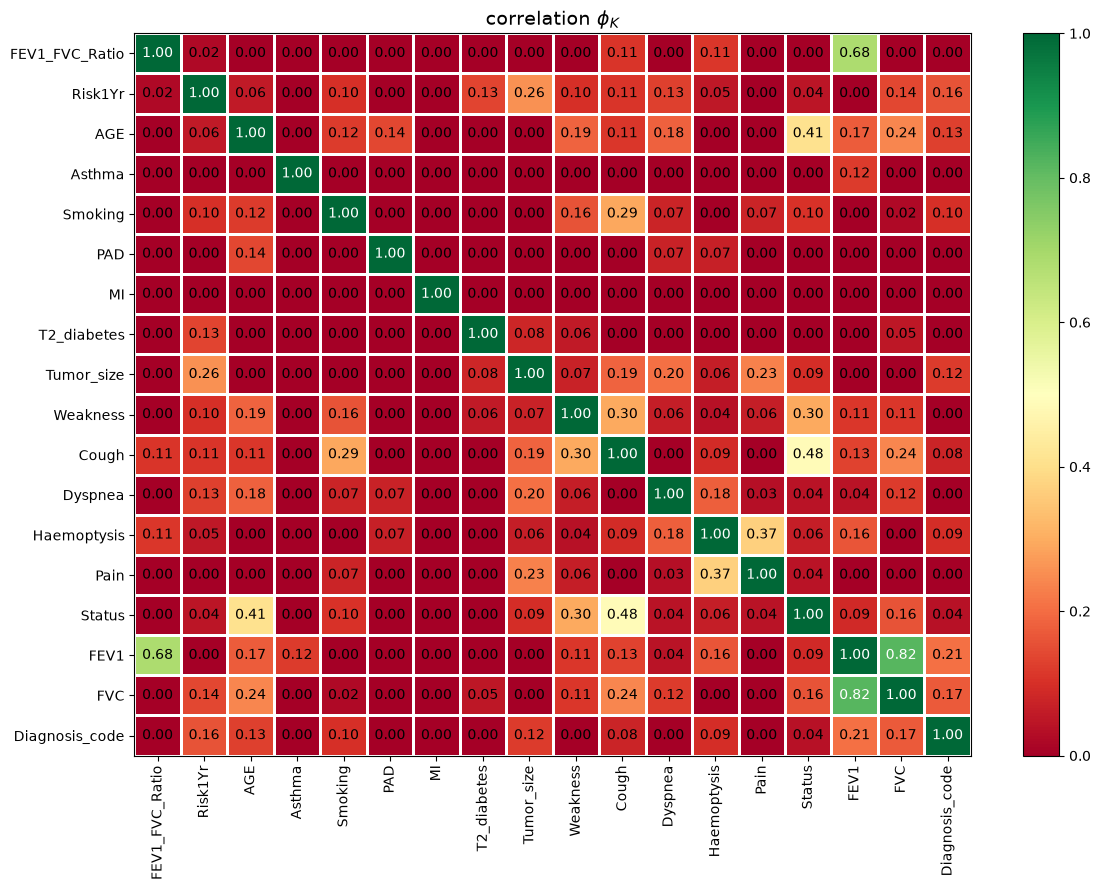

In [17]:
# @title ─────────── Phi-K Correlation Heatmap ───────────
from phik.report import plot_correlation_matrix
phik_overview = df.phik_matrix()

plot_correlation_matrix(phik_overview.values,
                        x_labels=phik_overview.columns,
                        y_labels=phik_overview.index,
                        vmin=0, vmax=1,
                        title=r"correlation $\phi_K$",
                        fontsize_factor=1.0,
                        figsize=(12, 9))
plt.tight_layout()
plt.show()

The correlation heat map above using the Phi_K constant calculated for each variable pair has many zeros and numbers very close to zero, indicating many of these may not have any association. A few of the higher values include variables that make sense to be correlated, like FEV1 and FVC with a constant of 0.82, and FEV1 and FEV1_FVC_Ratio with a constant of 0.68. Some of the interesting correlations may not be as strong, as they are below 0.5, but show some relationship. These include Status and Age with a constant of 0.41. Status and the presence of a cough before surgery with a constant of 0.48. The highest correlation constant with the outcome, Risk1Yr, is 0.26 with the size of the original tumor variable.

### Proportion of Missing Data | Imputation Method Suggestion
As some physiologically impossible values were removed earlier in this notebook, there are now 14 missing values for two variables. These might need to be imputed, but depending on the proportion of missing to total instances, there are different methods for this.

In [18]:
# Check proportion of missing values for all variables
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2)
})

missing = missing[missing['Missing Count'] > 0].sort_values('Missing %', ascending=False)

def flag_missing(pct):
    if pct < 5:
        return '✓ Safe — simple imputation (median)'
    elif pct <= 20:
        return '⚠ Moderate — model-based imputation; check mechanism'
    else:
        return '✗ High — consider missingness indicator + feature removal'

missing['Recommendation'] = missing['Missing %'].apply(flag_missing)

print(f"Total features with missing values: {len(missing)} of {df.shape[1]}\n")
display(missing)

Total features with missing values: 2 of 18



,Missing Count,Missing %,Recommendation
FEV1,14,2.98,✓ Safe — simple imputation (median)
FEV1_FVC_Ratio,14,2.98,✓ Safe — simple imputation (median)


Even though the above recommendation is to perform a simple imputation with the median for the 14 missing values in both FEV1 and FEV1/FVC ratio, this will wait until after the training and test data split to prevent data leakage.

### Create a 3D Surface Plot
This code requires additional libraries: `mpl_toolkits.mplot3d` import `Axes3D` and `scipy.interpolate` import `griddata`.

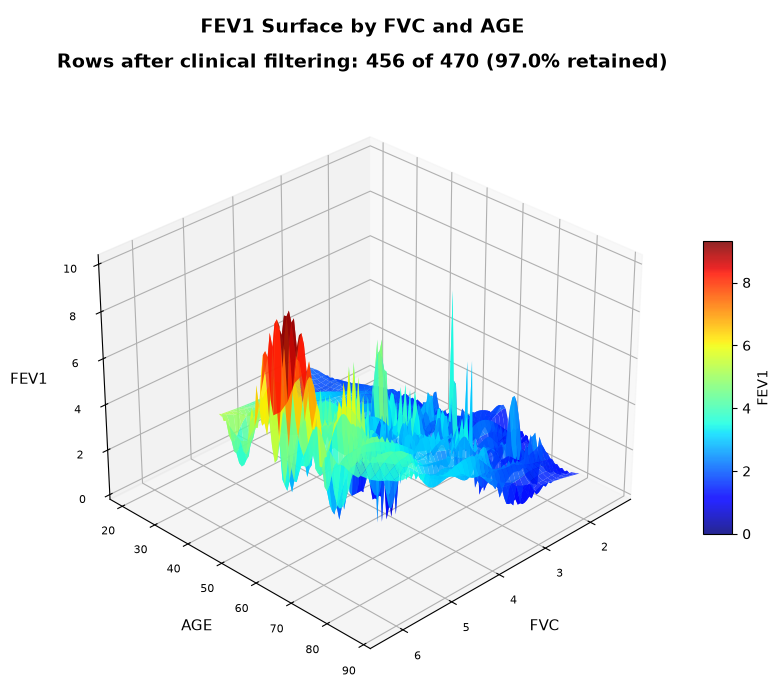

In [19]:
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata

def surface_plot_3d(df, x_col, y_col, z_col, title=None, cmap='jet'):
    """
    A new function for creating a 3D surface plot for three numeric variables.

    Parameters
    ----------
    df    : DataFrame
    x_col : str — variable plotted on the x-axis
    y_col : str — variable plotted on the y-axis
    z_col : str — variable plotted on the z-axis (surface height)
    title : str — plot title (optional)
    cmap  : str — colormap (default: 'jet')

    """
    # Apply clinical filters that were used above to remove 14 very unlikely values for FEV1. Adds documentation for the removal.
    df_clean = df[
        (df['FEV1'] < 10)
    ].copy()

    x = df_clean[x_col].values
    y = df_clean[y_col].values
    z = df_clean[z_col].values

    xi = np.linspace(x.min(), x.max(), 100)
    yi = np.linspace(y.min(), y.max(), 100)
    xi, yi = np.meshgrid(xi, yi)

    # Interpolate z values onto the grid
    zi = griddata((x, y), z, (xi, yi), method='cubic')

    # Clip negative interpolation artifacts
    zi = np.clip(zi, 0, None)

    # Plot
    fig = plt.figure(figsize=(10, 7))
    ax  = fig.add_subplot(111, projection='3d')

    surf = ax.plot_surface(
        xi, yi, zi,
        cmap=cmap,
        edgecolor='none',
        alpha=0.85
    )

    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label=z_col)

    ax.set_title(
        f"{title or f'{z_col} by {x_col} and {y_col}'}\n"
        f"Rows after clinical filtering: {len(df_clean)} of {len(df)} "
        f"({len(df_clean) / len(df) * 100:.1f}% retained)",
        fontsize=14, fontweight='bold', pad=20,
        linespacing=1.8
    )

    ax.set_xlabel(x_col, fontsize=11, labelpad=10)
    ax.set_ylabel(y_col, fontsize=11, labelpad=10)
    ax.set_zlabel(z_col, fontsize=11, labelpad=10)

    # Reduce tick label size
    for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
        axis.set_tick_params(labelsize=8)

    ax.view_init(elev=30, azim=45)
    plt.tight_layout()
    plt.show()

# ── Plot 1: FVC × Age → FEV1 ───────────────────────────────
surface_plot_3d(
    df,
    x_col='FVC',
    y_col='AGE',
    z_col='FEV1',
    title='FEV1 Surface by FVC and AGE'
)
print()

This 3D surface map highlights the importance of age when looking at lung function. As displayed with the red peak, the higher FEV1 values tend to be younger, not just with also higher FVC values.

### Final Data Pre-Processing:
The categorical variables first need to be converted into numerical values for models and analyses to fully interpret them. The nominal categorical variables, including the binary variables, can use One Hot Encoding. While the ordinal categorical variables, like Status and Tumor size, need to use Ordinal Encoding.

These require the additional libraries `sklearn.preprocessing` import `OneHotEncoder` and import `OrdinalEncoder`.


In [20]:
# @title ─────────── One Hot Encoding ───────────

from sklearn.preprocessing import OneHotEncoder

nominal_cols = ['Diagnosis_code', 'Pain', 'Haemoptysis', 'Dyspnea', 'Cough', 'Weakness', 'T2_diabetes', 'MI', 'PAD', 'Smoking', 'Asthma', 'Risk1Yr']

if nominal_cols:
    ohe = OneHotEncoder(sparse_output=False, drop='first')  # drop='first' avoids dummy variable trap
    ohe_array = ohe.fit_transform(df[nominal_cols])
    ohe_cols  = ohe.get_feature_names_out(nominal_cols)
    df_ohe    = pd.DataFrame(ohe_array, columns=ohe_cols, index=df.index)
    df        = pd.concat([df.drop(columns=nominal_cols), df_ohe], axis=1)
    print(f"One Hot Encoding applied to: {nominal_cols}")
    print(f"New columns created: {list(ohe_cols)}\n")
else:
    print("No nominal categorical columns specified for One Hot Encoding.\n")

One Hot Encoding applied to: ['Diagnosis_code', 'Pain', 'Haemoptysis', 'Dyspnea', 'Cough', 'Weakness', 'T2_diabetes', 'MI', 'PAD', 'Smoking', 'Asthma', 'Risk1Yr']
New columns created: ['Diagnosis_code_DGN2', 'Diagnosis_code_DGN3', 'Diagnosis_code_DGN4', 'Diagnosis_code_DGN5', 'Diagnosis_code_DGN6', 'Diagnosis_code_DGN8', 'Pain_T', 'Haemoptysis_T', 'Dyspnea_T', 'Cough_T', 'Weakness_T', 'T2_diabetes_T', 'MI_T', 'PAD_T', 'Smoking_T', 'Asthma_T', 'Risk1Yr_T']



In [21]:
# @title ─────── Ordinal Encoding ────────

from sklearn.preprocessing import OrdinalEncoder

# Define column names and their ordered categories
ordinal_cols = {
     'Status': ['PRZ0', 'PRZ1', 'PRZ2'],      # According to the Zubrod scale (or ECOG-PS scale, PRZ0 represents no restrictions from disease, fully active, while PRZ2 represents the ability to take care of oneself, but is restricted by disease and is unable to work.
     'Tumor_size': ['OC11', 'OC12', 'OC13', 'OC14'] # OC11 is the smallest size, while OC14 is the largest.
}

if ordinal_cols:
    oe = OrdinalEncoder(categories=[v for v in ordinal_cols.values()])
    df[list(ordinal_cols.keys())] = oe.fit_transform(df[list(ordinal_cols.keys())])
    print(f"Ordinal Encoding applied to: {list(ordinal_cols.keys())}\n")
else:
    print("No ordinal categorical columns specified for Ordinal Encoding.\n")

Ordinal Encoding applied to: ['Status', 'Tumor_size']



ECOG Performance Status Scale. (n.d.). ECOG-ACRIN Cancer Research Group. Retrieved October 16, 2026, from https://ecog-acrin.org/resources/ecog-performance-status/


In [22]:
# Confirm the results of the encoding on the dataframe.

df.head()

,FVC,FEV1,Status,Tumor_size,AGE,FEV1_FVC_Ratio,Diagnosis_code_DGN2,Diagnosis_code_DGN3,Diagnosis_code_DGN4,Diagnosis_code_DGN5,...,Haemoptysis_T,Dyspnea_T,Cough_T,Weakness_T,T2_diabetes_T,MI_T,PAD_T,Smoking_T,Asthma_T,Risk1Yr_T
0,2.88,2.16,1.0,3.0,60.0,0.750,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,3.40,1.88,0.0,1.0,51.0,0.553,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2.76,2.08,1.0,0.0,59.0,0.754,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,3.68,3.04,0.0,0.0,54.0,0.826,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2.44,0.96,2.0,0.0,73.0,0.393,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0


## Inferential Statistics:
As there are both parametric and non-parametric tests, to determine which tests should be run, a few assumptions need to be tested. For Parametric tests, it is assumed the distributions of the continuous variables used in the analyses are normal, or close enough, with a large enough sample size, according to the Central Limit Theorem. (math formulas are from Foundations of Biostatistics HSE712 Class notes).



### Levene's Test: testing for Equal Variances
Another assumption is that the continuous variables have equal or almost equal variance for the two different outcomes. This will be tested below with Levene's Test.

$H_O$: the variances are equal across groups

$H_A$: the variances are not equal across groups

This test requires another library: from `scipy` import `stats`.

In [23]:
from scipy import stats

group0 = df[df['Risk1Yr_T'] == 0]['FEV1_FVC_Ratio'].dropna()
group1 = df[df['Risk1Yr_T'] == 1]['FEV1_FVC_Ratio'].dropna()

stat, p = stats.levene(group0, group1)
print(f"Levene's Test — FEV1/FVC Ratio by Outcome")
print(f"  F = {stat:.4f},  p = {p:.4f}")
print(f"  {'✓ Equal variances — proceed with standard t-test' if p > 0.05 else '✗ Unequal variances — use Welch t-test (equal_var=False) or Mann-Whitney U'}")

Levene's Test — FEV1/FVC Ratio by Outcome
  F = 0.1142,  p = 0.7356
  ✓ Equal variances — proceed with standard t-test


According to the Levene's Test, the equal variance assumption has been met. The p-value resulted as 0.7356, which is not less than 0.05, and so the Null Hypothesis that the variances of the FEV1/FVC Ratio are equal across outcome groups, cannot be rejected. The parametric t-test can be performed to compare means of the FEV1/FVC Ratio variable across outcome groups.

## ──────── Independent Samples Two-sided t-test ────────

Tests whether the means of two independent groups differ significantly.

The t-score, or test statistic, is the deviation from the expected mean difference under the null hypothesis, that the two group means are equal.

$H_O$: $\mu_1$ = $\mu_2$

$H_A$: $\mu_1\ne\mu_2$ (two-sided)

$a$ = 0.05

When $df=(n_1+n_2-2)$ and variances are assumed equal, as shown above using Levene's test, use pooled variances:

$$t=\frac{(\bar{x_1}-\bar{x_2})-(\mu_1-\mu_2)}{s_p \sqrt{\frac{1}{n_1} + \frac{1}{n_2}}}\$$





Independent Samples t-Test — FEV1/FVC Ratio by Outcome
  Survive (0): n=387, mean=0.774, SD=0.163
  Did not survive    (1): n=69, mean=0.745, SD=0.109
  t(454) = 1.4485
  p-value   = 0.1482
  Cohen's d = 0.189  (small)

  ✗ Fail to reject H₀ — no significant difference in mean FEV1/FVC Ratio between groups


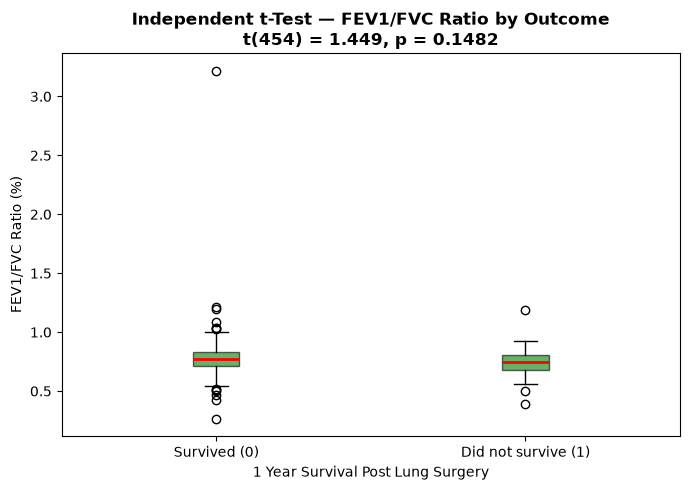

In [24]:
# @title ──────── Independent Samples Two-sided t-test ────────

# Using the same groups that were created above for the Levene's test.

t_stat, p_val = stats.ttest_ind(group0, group1, equal_var=True) # equal variances assumed after Levene's test, will now use pooled variances in calculation.

# Effect size: Cohen's d (in standard deviation units, to better describe difference in means. (https://www.spss-tutorials.com/cohens-d/))
pooled_sd = np.sqrt(((len(group0) - 1) * group0.std()**2 +
                     (len(group1) - 1) * group1.std()**2) /
                    (len(group0) + len(group1) - 2))
cohens_d = (group0.mean() - group1.mean()) / pooled_sd

print("Independent Samples t-Test — FEV1/FVC Ratio by Outcome")
print(f"  Survive (0): n={len(group0)}, mean={group0.mean():.3f}, SD={group0.std():.3f}")
print(f"  Did not survive    (1): n={len(group1)}, mean={group1.mean():.3f}, SD={group1.std():.3f}")
print(f"  t({len(group0)+len(group1)-2}) = {t_stat:.4f}")
print(f"  p-value   = {p_val:.4f}")
print(f"  Cohen's d = {cohens_d:.3f}  "
      f"({'small' if abs(cohens_d)<0.5 else 'medium' if abs(cohens_d)<0.8 else 'large'})")
print()
if p_val < 0.05:
    print("  ✓ Reject H₀ — mean FEV1/FVC Ratio differs significantly between groups (p < 0.05)")
else:
    print("  ✗ Fail to reject H₀ — no significant difference in mean FEV1/FVC Ratio between groups")

# Visualization
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([group0, group1],
           tick_labels=['Survived (0)', 'Did not survive (1)'],
           patch_artist=True,
           boxprops=dict(facecolor='green', alpha=0.6),
           medianprops=dict(color='red', linewidth=2))
ax.set_title(f'Independent t-Test — FEV1/FVC Ratio by Outcome\n'
             f't({len(group0)+len(group1)-2}) = {t_stat:.3f}, p = {p_val:.4f}',
             fontweight='bold')
ax.set_xlabel('1 Year Survival Post Lung Surgery')
ax.set_ylabel('FEV1/FVC Ratio (%)')
plt.tight_layout()
plt.show()

### t-test Interpretation
Despite the difference in ranges for each outcome group, the resulting p-value of the t-test is 0.1482, higher than 0.05 and so, the Null Hypothesis, that the mean FEV1/FVC Ratios for each group are equal, cannot be rejected. The Cohen's D value is also considered small, at 0.189 SD. This might indicate that the FEV1/FVC Ratio is not an important variable in the outcome prediction.

## ──────── Chi-Square Test or Fisher's Exact Test  ────────

The Chi-Square Test is used to measure whether the the Outcome variable, surviving 1 year post lung surgery, is associated with the binary predictor variable, like Smoking or No Smoking.

The Fisher's Exact Test is used when any of the frequencies are less than 5.

$H_O$: The Outcome and Smoking variables are independent.

$H_A$: The Outcome and Smoking variables are associated.

When $df= (\text{# rows}-1)*(\text{# columns}-1)$:

$$X^2 = \sum_{i=1}^{\text{# cells}} \frac{(O_i -E_i)^2}{E_i}$$

$E_i$ = expected count for cell $i$.

$O_i$ = observed count for cell $i$.



Contingency Table — Smoking × Outcome


Risk1Yr_T,Did not survive (1),Survived (0),All
Smoking_T,,,
0.0,7,77,84
1.0,63,323,386
All,70,400,470



Expected Frequencies:


Risk1Yr_T,0.0,1.0
Smoking_T,,
0.0,71.49,12.51
1.0,328.51,57.49



Minimum expected frequency: 12.51

Chi-Square Test of Independence
  χ²(1) = 2.8711
  p-value   = 0.0902
  Cramér's V = 0.078  (small)
  ✗ Fail to reject H₀ — no significant association detected


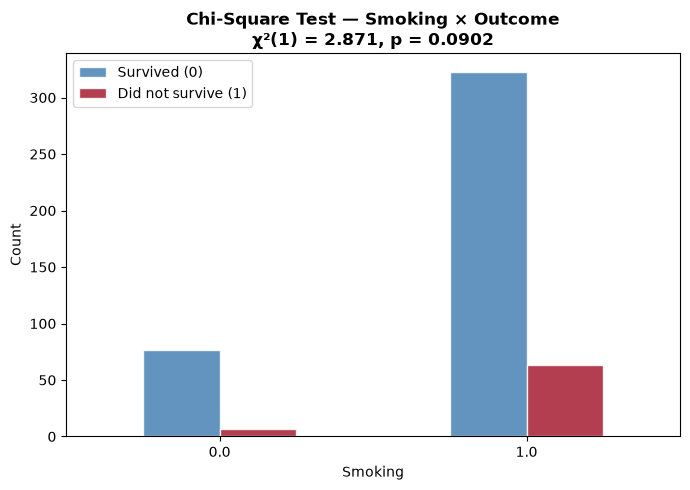

In [25]:
# @title ──────── Chi-Square Test or Fisher's Exact Test for Homogeneity ────────

contingency_table = pd.crosstab(
    df['Smoking_T'],
    df['Risk1Yr_T'].map({0: 'Survived (0)', 1: 'Did not survive (1)'}),
    margins=True
)
print("Contingency Table — Smoking × Outcome")
display(contingency_table)

ct_no_margins = pd.crosstab(df['Smoking_T'], df['Risk1Yr_T'])
chi2_stat, p_chi2, dof, expected = stats.chi2_contingency(ct_no_margins)

expected_df = pd.DataFrame(expected,
                           index=ct_no_margins.index,
                           columns=ct_no_margins.columns)
print("\nExpected Frequencies:")
display(expected_df.round(2))

min_expected = expected.min()
print(f"\nMinimum expected frequency: {min_expected:.2f}")

if min_expected >= 5:
    n = ct_no_margins.values.sum()
    min_dim = min(ct_no_margins.shape) - 1
    cramers_v = np.sqrt(chi2_stat / (n * min_dim))

    print("\nChi-Square Test of Independence")
    print(f"  χ²({dof}) = {chi2_stat:.4f}")
    print(f"  p-value   = {p_chi2:.4f}")
    print(f"  Cramér's V = {cramers_v:.3f}  "
          f"({'small' if cramers_v<0.3 else 'medium' if cramers_v<0.5 else 'large'})")
    if p_chi2 < 0.05:
        print("  ✓ Reject H₀ — Smoking and Outcome are significantly associated")
    else:
        print("  ✗ Fail to reject H₀ — no significant association detected")
else:
    print("\nFisher's Exact Test (minimum expected frequency < 5)")
    a = ct_no_margins.iloc[0, 0]
    b = ct_no_margins.iloc[0, 1]
    c = ct_no_margins.iloc[1, 0]
    d = ct_no_margins.iloc[1, 1]
    odds_ratio, p_fisher = stats.fisher_exact([[a, b], [c, d]])
    print(f"  Odds Ratio = {odds_ratio:.4f}")
    print(f"  p-value    = {p_fisher:.4f}")
    if p_fisher < 0.05:
        print("  ✓ Reject H₀ — Smoking and Outcome are significantly associated")
    else:
        print("  ✗ Fail to reject H₀ — no significant association detected")

# Visualization
fig, ax = plt.subplots(figsize=(7, 5))
ct_plot = pd.crosstab(df['Smoking_T'], df['Risk1Yr_T'])
ct_plot.plot(kind='bar', ax=ax, color=['steelblue', '#A51C30'],
             edgecolor='white', alpha=0.85)
ax.set_title(f'Chi-Square Test — Smoking × Outcome\n'
             f'χ²({dof}) = {chi2_stat:.3f}, p = {p_chi2:.4f}', fontweight='bold')
ax.set_xlabel('Smoking')
ax.set_ylabel('Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(['Survived (0)', 'Did not survive (1)'])
plt.tight_layout()
plt.show()

### Chi-Squared Test Interpretation
The Chi-Square Test resulted in a p-value of 0.0902, which is higher than 0.05 and so the null hypothesis, that there is no significant association between Smoking and Outcome, cannot be rejected. This indicates that Smoking and Outcome are independent from each other.



---


## **Supervised Machine Learning Models for binary classification**
Models that will be trained and tested:
 - Logistic Regression
 - Support Vector Machine (SVM)
 - Decision Tree classifiers

Model evaluation methods:
 - confusion matrices
 - classification reports
 - AUC-ROC curves

 Cross-validation and hyperparameter tuning will be performed on each model and again evaluated to find the best of the six models at predicting the outcome.


## Importing required libraries for building these machine learning models



In [26]:
# =============================================================================
# SUPERVISED MACHINE LEARNING — CLASSIFICATION
# =============================================================================

# Core scientific computing, uncomment if not already imported above
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# import math
# import warnings
# warnings.filterwarnings("ignore")

# =============================================================================
# Preprocessing
# =============================================================================
from sklearn.preprocessing import (
    StandardScaler,
    PowerTransformer,
    LabelEncoder
)
from sklearn.impute import KNNImputer

# =============================================================================
# Model selection and pipeline
# =============================================================================
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.pipeline import Pipeline

# =============================================================================
# Class imbalance
# =============================================================================
%pip install imbalanced-learn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# =============================================================================
# Classifiers — Module 3
# =============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# =============================================================================
# Evaluation metrics
# =============================================================================
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)
from sklearn.metrics import make_scorer

# =============================================================================
# Reproducibility
# =============================================================================
RANDOM_STATE = 17
np.random.seed(RANDOM_STATE)

%matplotlib inline
sns.set_theme(style="whitegrid")

print("=" * 60)
print("Module 3 libraries loaded successfully.")
print(f"Random seed set to {RANDOM_STATE}.")
print("=" * 60)


Module 3 libraries loaded successfully.
Random seed set to 17.


In [27]:
# @title ──────── Define Features and Target ────────

TARGET = 'Risk1Yr_T'

X = df.drop(columns=[TARGET])
y = df[TARGET]

print(f"Feature matrix shape  (X): {X.shape}")
print(f"Target vector shape   (y): {y.shape}")
print(f"\nClass distribution:")
print(y.value_counts())
print(f"\nClass proportions:")
print(y.value_counts(normalize=True).round(3))


Feature matrix shape  (X): (470, 22)
Target vector shape   (y): (470,)

Class distribution:
Risk1Yr_T
0.0    400
1.0     70
Name: count, dtype: int64

Class proportions:
Risk1Yr_T
0.0    0.851
1.0    0.149
Name: proportion, dtype: float64


In [28]:
# @title ──────── Train / Test Split ────────

# =============================================================================
# An 80/20 Train/Test split, using stratification to maintain class proportions.
#
# stratify=y ensures that when the training and test sets are split, they have
# the same, or nearly the same, ratio of each outcome group.
#
# The test set is not used until model evaluation.
# Hyperparameter tuning with cross-validation will only be performed on the
# training set, instead of also being influenced by the test set.
# =============================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("=" * 60)
print("Train / Test Split Summary")
print("=" * 60)
print(f"Training set:  {X_train.shape[0]} observations ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set:      {X_test.shape[0]} observations ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))
print(f"\nTest class distribution:")
print(y_test.value_counts(normalize=True).round(3))


Train / Test Split Summary
Training set:  376 observations (80.0%)
Test set:      94 observations (20.0%)

Training class distribution:
Risk1Yr_T
0.0    0.851
1.0    0.149
Name: proportion, dtype: float64

Test class distribution:
Risk1Yr_T
0.0    0.851
1.0    0.149
Name: proportion, dtype: float64


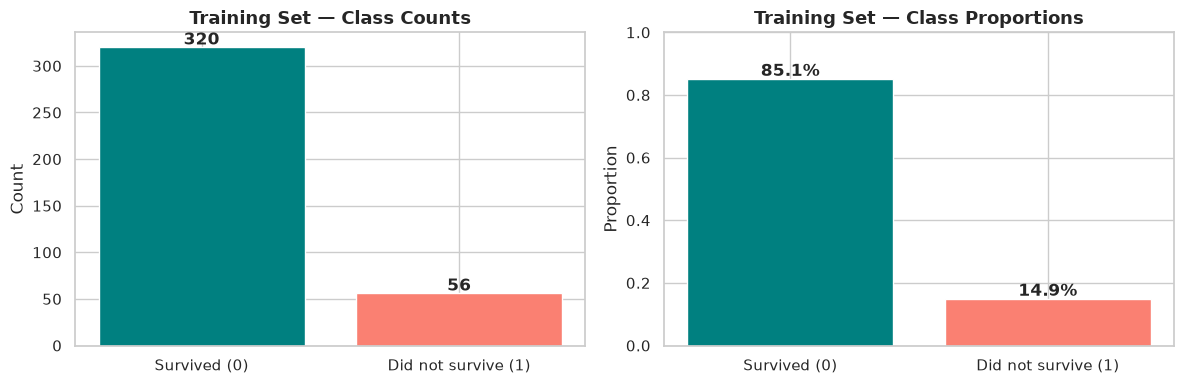

Imbalance ratio: 5.71
Strategy: class_weight='balanced' applied to all classifiers.
          SMOTE can be applied inside ImbPipeline for select models.


In [29]:
# @title ──────── Checking Class Imbalance ────────

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Class counts
counts = y_train.value_counts()
axes[0].bar(
    ['Survived (0)', 'Did not survive (1)'],
    counts.values,
    color=['teal', 'salmon'],
    edgecolor='white'
)
axes[0].set_title('Training Set — Class Counts', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 3, str(v), ha='center', fontweight='bold')

# Class proportions
proportions = y_train.value_counts(normalize=True)
axes[1].bar(
    ['Survived (0)', 'Did not survive (1)'],
    proportions.values,
    color=['teal', 'salmon'],
    edgecolor='white'
)
axes[1].set_title('Training Set — Class Proportions', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Proportion')
axes[1].set_ylim(0, 1)
for i, v in enumerate(proportions.values):
    axes[1].text(i, v + 0.01, f'{v:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

imbalance_ratio = counts.max() / counts.min()
print(f"Imbalance ratio: {imbalance_ratio:.2f}")
print(f"Strategy: class_weight='balanced' applied to all classifiers.")
print(f"          SMOTE can be applied inside ImbPipeline for select models.")


Synthetic Minority Over-sampling Technique (SMOTE) - generates synthetic minority class observations in the training set, using K nearest neighbors. This is to help with the unbalanced outcome variable. However, the imbalance will only be addressed with class_weight='balanced' in the models below.

In [30]:
# @title ──────── Creating Shared Evaluation Functions ────────

def get_metrics_score(model, X_train, X_test, y_train, y_test, verbose=True):
    """
    Computes Accuracy, Recall, Precision, F1-score, and AUC-ROC
    for both training and test sets.

    Parameters
    ----------
    model    : fitted sklearn estimator or Pipeline
    X_train  : training feature matrix
    X_test   : test feature matrix
    y_train  : training target vector
    y_test   : test target vector
    verbose  : if True, prints results to console

    Returns
    -------
    list : [train_acc, test_acc, train_recall, test_recall,
            train_precision, test_precision, train_f1, test_f1,
            train_auc, test_auc]
    """
    y_pred_train = model.predict(X_train)
    y_pred_test  = model.predict(X_test)

    # Compute AUC-ROC (requires probability scores)
    if hasattr(model, 'predict_proba'):
        train_auc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
        test_auc  = roc_auc_score(y_test,  model.predict_proba(X_test)[:, 1])
    elif hasattr(model, 'decision_function'):
        train_auc = roc_auc_score(y_train, model.decision_function(X_train))
        test_auc  = roc_auc_score(y_test,  model.decision_function(X_test))
    else:
        train_auc = test_auc = None

    train_acc  = accuracy_score(y_train, y_pred_train)
    test_acc   = accuracy_score(y_test,  y_pred_test)
    train_rec  = recall_score(y_train, y_pred_train)
    test_rec   = recall_score(y_test,  y_pred_test)
    train_prec = precision_score(y_train, y_pred_train)
    test_prec  = precision_score(y_test,  y_pred_test)
    train_f1   = f1_score(y_train, y_pred_train)
    test_f1    = f1_score(y_test,  y_pred_test)

    if verbose:
        print("=" * 50)
        print(f"{'Metric':<22} {'Train':>8}  {'Test':>8}")
        print("=" * 50)
        print(f"{'Accuracy':<22} {train_acc:>8.3f}  {test_acc:>8.3f}")
        print(f"{'Recall':<22} {train_rec:>8.3f}  {test_rec:>8.3f}")
        print(f"{'Precision':<22} {train_prec:>8.3f}  {test_prec:>8.3f}")
        print(f"{'F1-Score':<22} {train_f1:>8.3f}  {test_f1:>8.3f}")
        if train_auc is not None:
            print(f"{'AUC-ROC':<22} {train_auc:>8.3f}  {test_auc:>8.3f}")
        print("=" * 50)

    return [train_acc, test_acc, train_rec, test_rec,
            train_prec, test_prec, train_f1, test_f1,
            train_auc, test_auc]


def make_confusion_matrix(model, X, y_actual, title="Confusion Matrix"):
    """
    Generates a styled confusion matrix with counts and percentages.

    Parameters
    ----------
    model    : fitted sklearn estimator or Pipeline
    X        : feature matrix (e.g., X_test)
    y_actual : true class labels
    title    : plot title
    """
    y_predict = model.predict(X)
    cm = confusion_matrix(y_actual, y_predict)

    group_counts      = [f"{v:0.0f}" for v in cm.flatten()]
    group_percentages = [f"{v:.2%}"  for v in cm.flatten() / np.sum(cm)]
    labels = np.array([f"{c}\n{p}" for c, p in
                       zip(group_counts, group_percentages)]).reshape(2, 2)

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=labels,
        fmt='',
        cmap='Blues',
        xticklabels=['Predicted: No (0)', 'Predicted: Yes (1)'],
        yticklabels=['Actual: No (0)',    'Actual: Yes (1)'],
        ax=ax
    )
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=11)
    ax.set_xlabel('Predicted Label', fontsize=11)
    plt.tight_layout()
    plt.show()

    # Print classification report
    print("\nClassification Report:")
    print(classification_report(y_actual, y_predict,
                                target_names=['Survived', 'Did not survive']))


def plot_roc_curve(model, X_test, y_test, model_name="Model"):
    """
    Plots the ROC curve for a binary classifier.

    Parameters
    ----------
    model      : fitted sklearn estimator or Pipeline
    X_test     : test feature matrix
    y_test     : test target vector
    model_name : label for the legend
    """
    if hasattr(model, 'predict_proba'):
        y_scores = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_scores = model.decision_function(X_test)
    else:
        raise ValueError("Model does not support probability or decision scores.")

    fpr, tpr, thresholds = roc_curve(y_test, y_scores)
    auc_score = roc_auc_score(y_test, y_scores)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(fpr, tpr, color='#A51C30', lw=2,
            label=f'{model_name}  (AUC = {auc_score:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier (AUC = 0.500)')
    ax.fill_between(fpr, tpr, alpha=0.1, color='#A51C30')
    ax.set_xlabel('False Positive Rate (1 − Specificity)', fontsize=11)
    ax.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
    ax.set_title(f'ROC Curve — {model_name}', fontsize=13, fontweight='bold')
    ax.legend(fontsize=10)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.02])
    plt.tight_layout()
    plt.show()

    return auc_score


print("Evaluation functions defined successfully.")
print("  • get_metrics_score()")
print("  • make_confusion_matrix()")
print("  • plot_roc_curve()")


Evaluation functions defined successfully.
  • get_metrics_score()
  • make_confusion_matrix()
  • plot_roc_curve()


Enhancement 5: used the code above for the reusable functions from notebook, Dartmouth Programming_Additional Code, to be able to evaluate each model consistently, and will only need to call the three functions instead of repeating the whole chunk of code.

The metrics included in the function above are all important to know about the general models abilities. However, for this dataset, the primary metric will be Recall, as the weight of a False Negative is much higher than a False Positive and should be minimized as much as possible. This is due to this dataset being designed for binary classification for surviving at least up to one year after lung surgery for patients with lung cancer, and likely, if a patient is predicted to not make it through this period, then they would likely recieve extra care to try to increase the odds that they do. But if the model incorrectly predicts that they will survive at least up to 1 year with the current standard of care, they will not recieve this extra care and might be at even higher risk of dying during this period of concern. The next metric for evalution would be the ROC-AUC curve as this still takes into account Recall, or Sensitivity, but also includes the False Positive Rate as a balance, measuring a more general performance of the models.

In [31]:
# @title ──────── Logistic Regression - Baseline Model ────────

# =============================================================================
# Pipeline:
#   1. KNNImputer     — impute missing values
#   2. PowerTransformer — Yeo-Johnson normalization
#   3. StandardScaler — zero mean, unit variance
#   4. LogisticRegression — L2 regularization (default), balanced class weights
#       (L2 reduces overfitting by driving weights of features that don't
#       influence the model much close to 0, but are still in the model
#       (https://developers.google.com/machine-learning/glossary#L2_regularization))
#
# class_weight='balanced' automatically adjusts weights inversely proportional
# to class frequencies, addressing the class imbalance identified above.
# =============================================================================

lr_pipeline = Pipeline([
    ('imputer',     KNNImputer(n_neighbors=5)),
    ('transformer', PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scaler',      StandardScaler()),
    ('clf',         LogisticRegression(
                        penalty='l2',
                        C=1.0,
                        class_weight='balanced',
                        solver='lbfgs',
                        max_iter=1000,
                        random_state=RANDOM_STATE
                    ))
])

lr_pipeline.fit(X_train, y_train)

print("Logistic Regression — Baseline (L2, C=1.0)")
lr_scores = get_metrics_score(lr_pipeline, X_train, X_test, y_train, y_test)


Logistic Regression — Baseline (L2, C=1.0)
Metric                    Train      Test
Accuracy                  0.697     0.681
Recall                    0.696     0.714
Precision                 0.287     0.278
F1-Score                  0.406     0.400
AUC-ROC                   0.754     0.757


The metric values for the Training and Test datasets are fairly similar, and Recall and AUC-ROC are fairly high values. However, the values for Precision and the F1-score are pretty low, indicating that the model is better at preventing false negatives than false positives. This is the better alternative for this scenario if positive prediction would involve an increase in care, while a negative prediction would not involve an increase in care, which could be very detrimental to patients, as this involves survival after lung surgery.

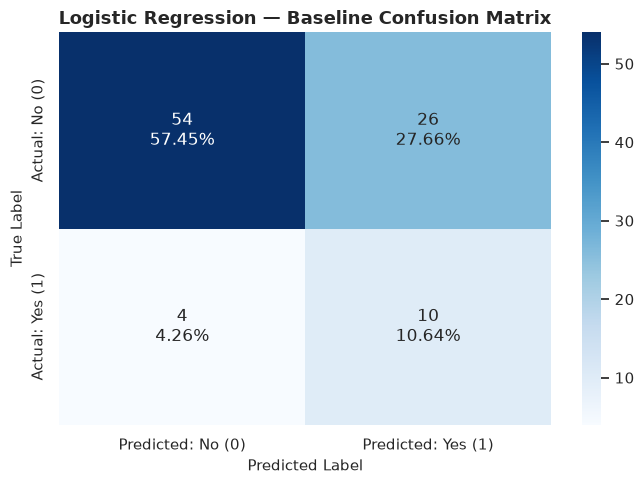


Classification Report:
                 precision    recall  f1-score   support

       Survived       0.93      0.68      0.78        80
Did not survive       0.28      0.71      0.40        14

       accuracy                           0.68        94
      macro avg       0.60      0.69      0.59        94
   weighted avg       0.83      0.68      0.73        94



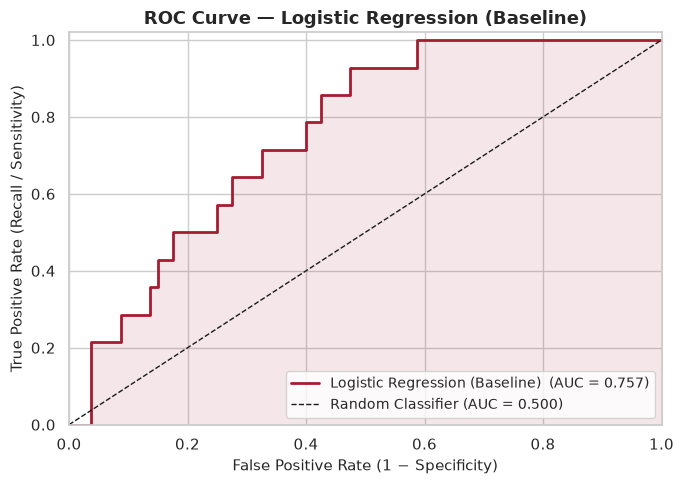

In [32]:
# @title ──────── Logistic Regression - Confusion Matrix and AUC-ROC Curve ────────

make_confusion_matrix(lr_pipeline, X_test, y_test,
                      title="Logistic Regression — Baseline Confusion Matrix")

lr_auc = plot_roc_curve(lr_pipeline, X_test, y_test,
                        model_name="Logistic Regression (Baseline)")


According to the ROC-AUC curve, with an AUC value of 0.757, the Baseline Logistic Regression model is better at predicting outcome than a random classifier. The Confusion Matrix does suggest that the False Negative rate for this model is low, at 4.26%, which is good. The False Positive rate is 27.66%, which is high, but the risks of a False Positive for patients in this scenario are less likely to be very high, however, this should not be ignored.

Logistic Regression — Learned Coefficients


,Feature,Coefficient (log-odds),Odds Ratio
20,Smoking_T,0.3982,1.4891
9,Diagnosis_code_DGN5,0.3935,1.4822
3,Tumor_size,0.3814,1.4643
10,Diagnosis_code_DGN6,-0.3360,0.7146
11,Diagnosis_code_DGN8,0.3019,1.3524
14,Dyspnea_T,0.2872,1.3328
18,MI_T,-0.2823,0.7541
21,Asthma_T,-0.2349,0.7907
6,Diagnosis_code_DGN2,0.2205,1.2467
12,Pain_T,0.1877,1.2065


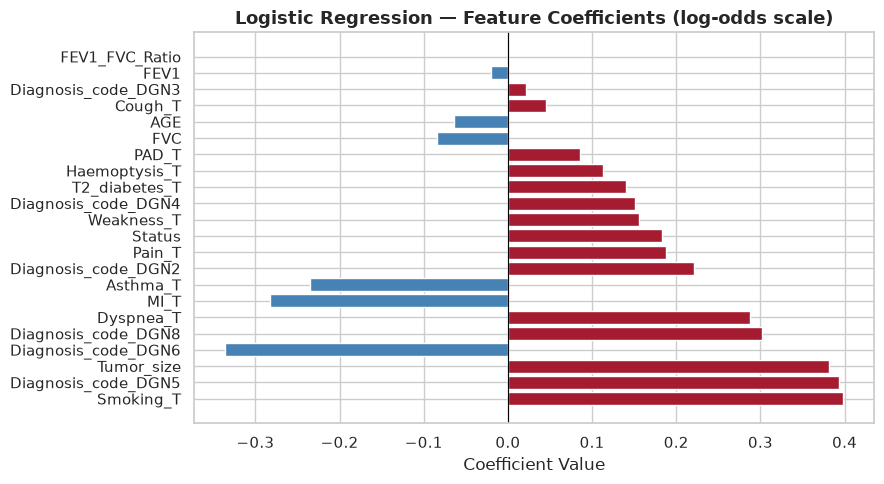

In [33]:

# @title ──────── Logistic Regression - Coefficient Interpretation ────────

lr_model = lr_pipeline.named_steps['clf']
feature_names = X_train.columns.tolist()

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient (log-odds)': lr_model.coef_[0],
    'Odds Ratio': np.exp(lr_model.coef_[0])
}).sort_values('Coefficient (log-odds)', key=abs, ascending=False)

print("Logistic Regression — Learned Coefficients")
display(coef_df.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#A51C30' if c > 0 else 'steelblue' for c in coef_df['Coefficient (log-odds)']]
ax.barh(coef_df['Feature'], coef_df['Coefficient (log-odds)'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression — Feature Coefficients (log-odds scale)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Coefficient Value')
plt.tight_layout()
plt.show()


### Overall Interpretation of Baseline Logistic Regression
Smoking is the feature that has the highest positive effect on the Outcome with an odds ratio of ~1.49, even though it was not found to be significantly associated with the Outcome in earlier Chi-squared testing. This might indicate that it still has the strongest relationship compared to the other variables. The feature with the highest negative effect on the Outcome, is Diagnosis codee DGN6, with an odds ratio of ~0.71. However, this dataset did not include the information behind the Diagnosis codes. Overall, this model is not perfect, but does minimize the false negatives, and does highlight possible features that have the most effect of the outcome.

In [34]:
# @title ──────── Logistic Regression - Hyperparameter Tuning with GridSearchCV ────────

lr_param_grid = {
    'clf__C':       [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'clf__penalty': ['l1', 'l2'],
    'clf__solver':  ['liblinear']   # liblinear supports both l1 and l2
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring='recall',          # optimize for primary metric, recall (minimize false negatives)
    cv=cv,
    n_jobs=-1,
    verbose=0
)

lr_grid.fit(X_train, y_train)

print(f"Best hyperparameters: {lr_grid.best_params_}")
print(f"Best cross-validated recall: {lr_grid.best_score_:.3f}")

lr_tuned = lr_grid.best_estimator_


Best hyperparameters: {'clf__C': 0.001, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
Best cross-validated recall: 0.627


Interestingly, the best recall value after cross-validation is actually lower than the baseline model. Below, the tuned model will be evaluated.

Logistic Regression — Tuned Model
Metric                    Train      Test
Accuracy                  0.628     0.628
Recall                    0.714     0.714
Precision                 0.244     0.244
F1-Score                  0.364     0.364
AUC-ROC                   0.735     0.725


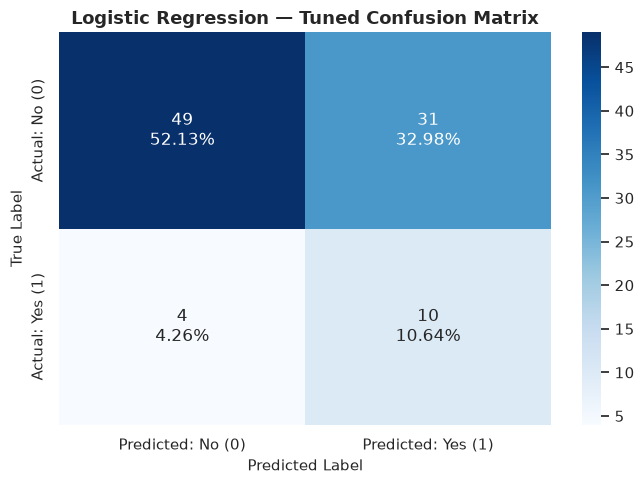


Classification Report:
                 precision    recall  f1-score   support

       Survived       0.92      0.61      0.74        80
Did not survive       0.24      0.71      0.36        14

       accuracy                           0.63        94
      macro avg       0.58      0.66      0.55        94
   weighted avg       0.82      0.63      0.68        94



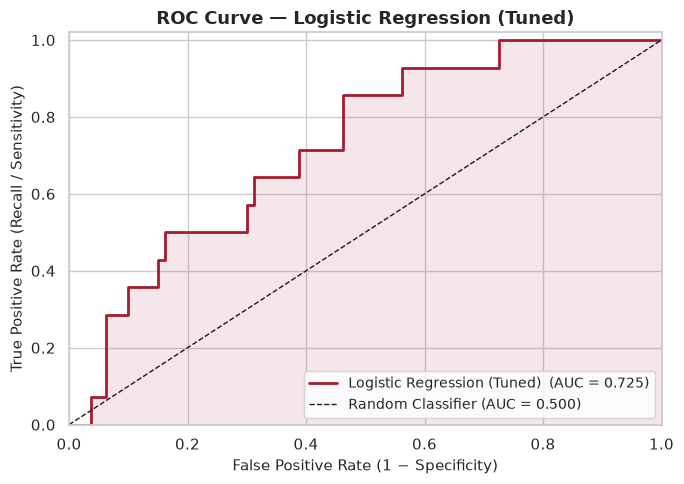

In [35]:
# @title ──────── Logistic Regression - Tuned Model Evaluation ────────

print("Logistic Regression — Tuned Model")
lr_tuned_scores = get_metrics_score(lr_tuned, X_train, X_test, y_train, y_test)

make_confusion_matrix(lr_tuned, X_test, y_test,
                      title="Logistic Regression — Tuned Confusion Matrix")

lr_tuned_auc = plot_roc_curve(lr_tuned, X_test, y_test,
                              model_name="Logistic Regression (Tuned)")


### Interpretation of the Tuned Logistic Regression

The Recall value for the test set of the tuned logistic regression model is the same as for the baseline model, at 0.714. However, the metrics for the Tuned model are much more similar between the Training and Testing datasets. The Confusion Matrix suggests that the False Negative rate remained the same as the Baseline model, 4.26%, but the False Positive rate increased to 32.98%, which indicates the worsening in the False Positive rate did not help improve the recall orhte False Negative rate. This makes the adjustment to be unnecessary, especially with incorrectly predicting a positive incorrectly to be about 1 out of 3. According to the ROC-AUC curve, with an AUC value of 0.725, the Tuned Logistic Regression model is better at predicting outcome than a random classifier, but slightly worse than the Baseline Logistic Regression Model.

In [36]:
# @title ──────── Support Vector Machine - Baseline Model ────────

# =============================================================================
# Pipeline:
#   1. KNNImputer     — impute missing values
#   2. PowerTransformer — Yeo-Johnson normalization
#   3. StandardScaler — required for SVM (distance-based algorithm)
#   4. SVC            — RBF kernel (Radial Basis Function), balanced class weights (Support Vector Classifier)
#
# probability=True enables predict_proba() for AUC-ROC computation.
# Note: this adds computational cost via Platt scaling (a probability calibration technique that turns output into probabilites (https://blog.trainindata.com/complete-guide-to-platt-scaling/))
# =============================================================================

svm_pipeline = Pipeline([
    ('imputer',     KNNImputer(n_neighbors=5)),
    ('transformer', PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scaler',      StandardScaler()),
    ('clf',         SVC(
                        kernel='rbf',
                        C=1.0,
                        gamma='scale',
                        class_weight='balanced',
                        probability=True,
                        random_state=RANDOM_STATE
                    ))
])

svm_pipeline.fit(X_train, y_train)

print("Support Vector Machine — Baseline (RBF kernel, C=1.0)")
svm_scores = get_metrics_score(svm_pipeline, X_train, X_test, y_train, y_test)


Support Vector Machine — Baseline (RBF kernel, C=1.0)
Metric                    Train      Test
Accuracy                  0.814     0.723
Recall                    0.768     0.500
Precision                 0.430     0.269
F1-Score                  0.551     0.350
AUC-ROC                   0.892     0.652


The baseline Support Vector Machine model has higher overall accuracy,  but much lower values in Test recall, at 0.5, which is the more critical parameter. All of the test values are lower than the training values of each metric, indicating that the training does not translate as well to different data from what it was trained on.

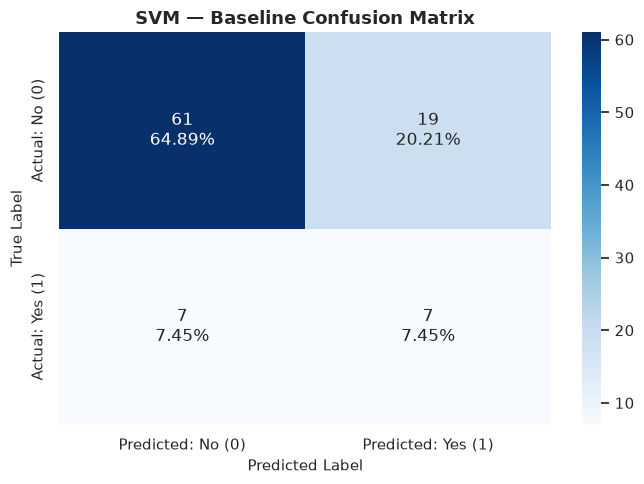


Classification Report:
                 precision    recall  f1-score   support

       Survived       0.90      0.76      0.82        80
Did not survive       0.27      0.50      0.35        14

       accuracy                           0.72        94
      macro avg       0.58      0.63      0.59        94
   weighted avg       0.80      0.72      0.75        94



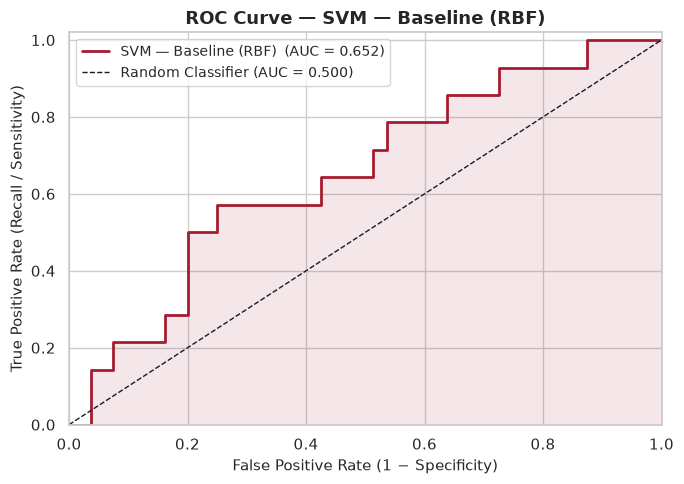

In [37]:
# @title ──────── SVM - Confusion Matrix and ROC-AUC Curve ────────

make_confusion_matrix(svm_pipeline, X_test, y_test,
                      title="SVM — Baseline Confusion Matrix")

svm_auc = plot_roc_curve(svm_pipeline, X_test, y_test,
                         model_name="SVM — Baseline (RBF)")


### Interpretation of Baseline Support Vector Machine model

According to the Confusion Matrix for the baseline SVM model, the False Negative rate (7.45%) is much higher than for the Logistic Regression models. The False positive rate has decreased, which is good, but not at the cost of the False Negative Rate. The AUC value for the Baseline SVM model is 0.652, which is only slightly better at predicting the outcome than a random classifier, but is lower than the AUC scores for both the baseline and tuned logistic regression models.

In [38]:
# @title ──────── SVM - Hyperparameter Tuning with GridSearchCV ────────

# =============================================================================
# Key hyperparameters:
#
#   C      — regularization (soft margin penalty)
#   kernel — type of kernel function
#   gamma  — kernel coefficient for RBF/poly (controls decision boundary complexity)
# =============================================================================

svm_param_grid = {
    'clf__C':      [0.1, 1.0, 10.0, 100.0],
    'clf__kernel': ['rbf', 'linear'],
    'clf__gamma':  ['scale', 'auto', 0.001, 0.01]
}

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring='recall',          # optimize for primary metric, recall (minimize false negatives)
    cv=cv,
    n_jobs=-1,
    verbose=0
)

svm_grid.fit(X_train, y_train)

print(f"Best hyperparameters: {svm_grid.best_params_}")
print(f"Best cross-validated recall: {svm_grid.best_score_:.3f}")

svm_tuned = svm_grid.best_estimator_

Best hyperparameters: {'clf__C': 0.1, 'clf__gamma': 0.001, 'clf__kernel': 'rbf'}
Best cross-validated recall: 1.000


The best cross-validated recall of 1.00 indicates that the Tuned SVM model might be overfit to the training data and so less able to generalize to other data. The full evaluation below will confirm this or not.

Support Vector Machine — Tuned Model
Metric                    Train      Test
Accuracy                  0.149     0.149
Recall                    1.000     1.000
Precision                 0.149     0.149
F1-Score                  0.259     0.259
AUC-ROC                   0.268     0.279


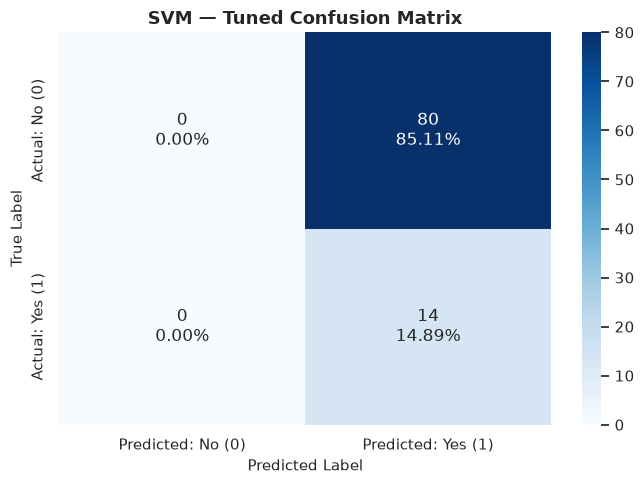


Classification Report:
                 precision    recall  f1-score   support

       Survived       0.00      0.00      0.00        80
Did not survive       0.15      1.00      0.26        14

       accuracy                           0.15        94
      macro avg       0.07      0.50      0.13        94
   weighted avg       0.02      0.15      0.04        94



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


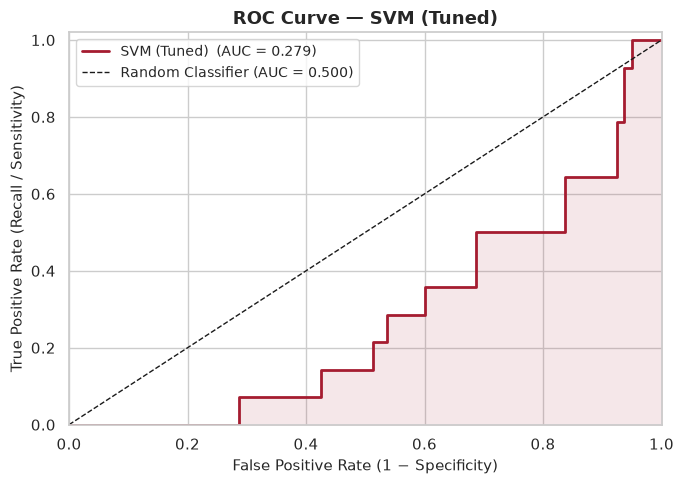

In [39]:
# @title ──────── Support Vector Machine - Tuned Model Evaluation ────────

print("Support Vector Machine — Tuned Model")
svm_tuned_scores = get_metrics_score(svm_tuned, X_train, X_test, y_train, y_test)

make_confusion_matrix(svm_tuned, X_test, y_test,
                      title="SVM — Tuned Confusion Matrix")

svm_tuned_auc = plot_roc_curve(svm_tuned, X_test, y_test,
                               model_name="SVM (Tuned)")


### Interpretation of Tuned Support Vector Machine model

Recall might be basically perfect, but every other metric decreased significantly. When looking at the Confusion Matrix, there were no False Negatives, but also no True Negatives, meaning the model did not predict any patient would survive to one year after lung surgery. This results in a very high False positive rate at 85.11%. The AUC value is 0.279, indicating this tuned SVM model is worse at predicting the outcome than a random classifier. If there is a cost to the increased level of care that can be harmful in other ways, like overwork the staff until the increased care no longer helps, then this is 100% positive prediction can be very harmful and unnecessary.

In [40]:
# @title ──────── Decision Tree Classifier - Baseline Model ────────

# =============================================================================
# Note: Decision Trees do not require feature scaling, removing transformation and scaling from pipeline.
# KNN imputation is still applied inside the pipeline to handle missing values.
# =============================================================================

dt_pipeline = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('clf',     DecisionTreeClassifier(
                    criterion='gini',
                    class_weight='balanced',
                    random_state=RANDOM_STATE
                ))
])

dt_pipeline.fit(X_train, y_train)

print("Decision Tree — Baseline (Gini, unconstrained depth)")
dt_scores = get_metrics_score(dt_pipeline, X_train, X_test, y_train, y_test)


Decision Tree — Baseline (Gini, unconstrained depth)
Metric                    Train      Test
Accuracy                  1.000     0.734
Recall                    1.000     0.143
Precision                 1.000     0.133
F1-Score                  1.000     0.138
AUC-ROC                   1.000     0.490


The baseline Decision Tree Classifier is overfit, as indicated by the perfect metric scores for the training dataset, but the metric values for the test set are very poor, except for the overall accuracy. But overall accuracy does not account for the different risks and benefits.

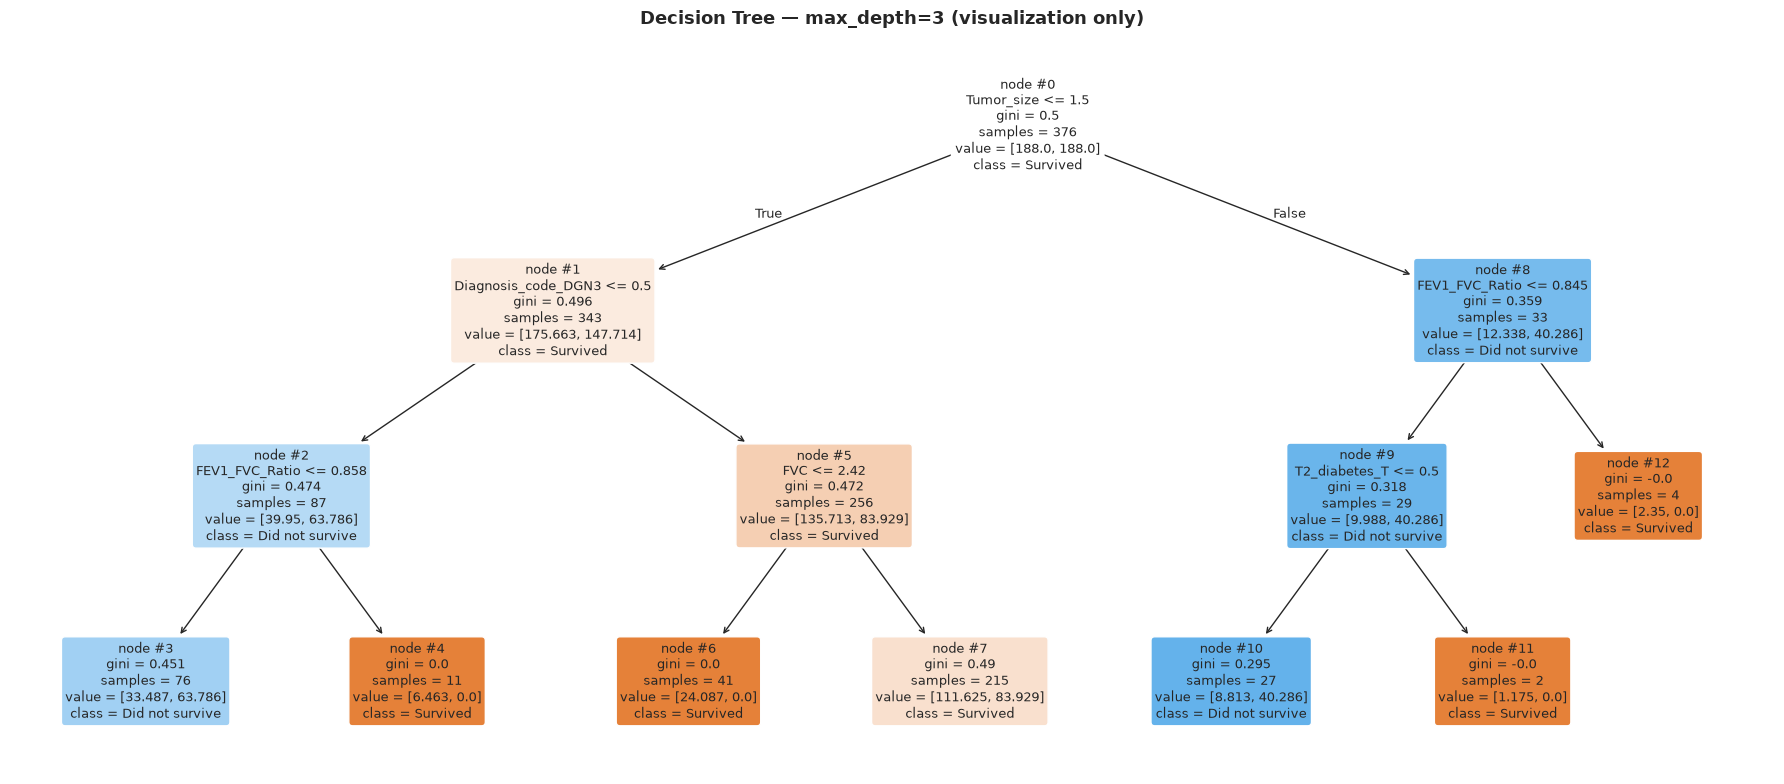

In [41]:
# @title ──────── Decision Tree - Visualizing the Structure ────────

# =============================================================================
# Visualization is restricted to max_depth=3 for readability.
# =============================================================================

dt_viz = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('clf',     DecisionTreeClassifier(
                    criterion='gini',
                    max_depth=3,
                    class_weight='balanced',
                    random_state=RANDOM_STATE
                ))
])
dt_viz.fit(X_train, y_train)

plt.figure(figsize=(18, 8))
plot_tree(
    dt_viz.named_steps['clf'],
    feature_names=X_train.columns.tolist(),
    class_names=['Survived', 'Did not survive'],
    filled=True,
    rounded=True,
    fontsize=9,
    node_ids=True
)
plt.title('Decision Tree — max_depth=3 (visualization only)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


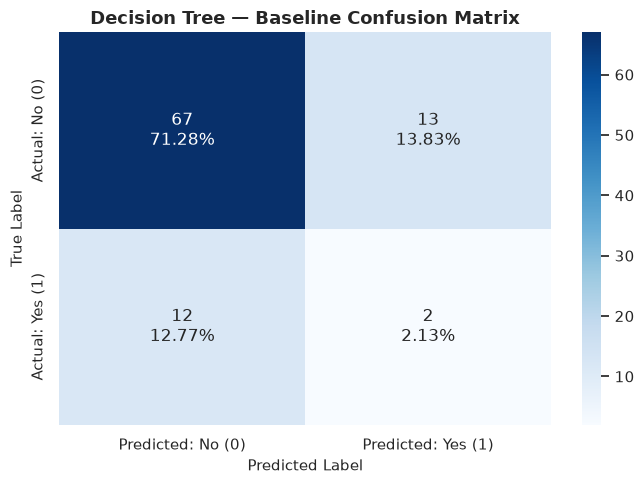


Classification Report:
                 precision    recall  f1-score   support

       Survived       0.85      0.84      0.84        80
Did not survive       0.13      0.14      0.14        14

       accuracy                           0.73        94
      macro avg       0.49      0.49      0.49        94
   weighted avg       0.74      0.73      0.74        94



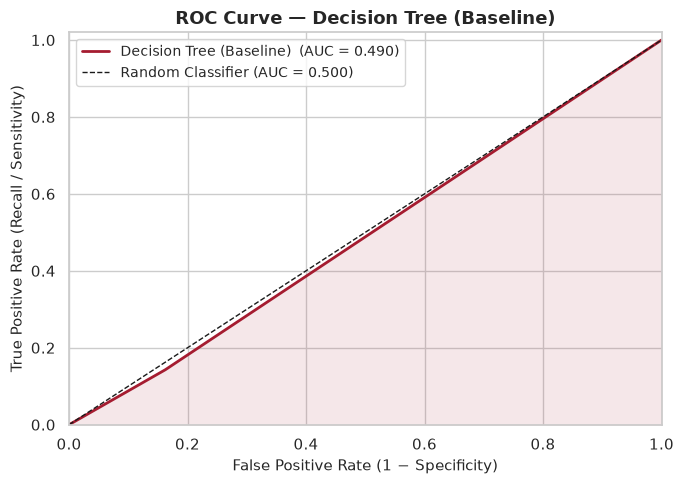

In [42]:
# @title ──────── Decision Tree - Confusion Matrix and ROC-AUC Curve ────────

make_confusion_matrix(dt_pipeline, X_test, y_test,
                      title="Decision Tree — Baseline Confusion Matrix")

dt_auc = plot_roc_curve(dt_pipeline, X_test, y_test,
                        model_name="Decision Tree (Baseline)")


### Interpretation of Baseline Decision Tree model

According to the Confusion Matrix, this model has the highest False Negative rate at 12.77%, which is the highest of the models so far, aligning with the Recall test value of 0.143. With an AUC value of 0.490, the baseline decision tree model is slightly worse at predicting the outcome than a random classifier, indicating this is also not a good classifying model for this data.

In [43]:
# @title ──────── Decision Tree - Hyperparameter Tuning with GridSearchCV ────────

dt_param_grid = {
    'clf__max_depth':          list(np.arange(3, 15)),
    'clf__criterion':          ['gini', 'entropy'],
    'clf__min_samples_split':  [2, 5, 10, 20],
    'clf__min_samples_leaf':   [1, 2, 5, 10],
    'clf__max_features':       ['sqrt', 'log2', None],
    'clf__min_impurity_decrease': [0.0, 0.0001, 0.001]
}

dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    scoring='recall',                     # optimize for primary metric, recall (minimize false negatives)
    cv=cv,
    n_jobs=-1,
    verbose=0
)

dt_grid.fit(X_train, y_train)

print(f"Best hyperparameters: {dt_grid.best_params_}")
print(f"Best cross-validated recall: {dt_grid.best_score_:.3f}")

dt_tuned = dt_grid.best_estimator_


Best hyperparameters: {'clf__criterion': 'gini', 'clf__max_depth': np.int64(6), 'clf__max_features': 'sqrt', 'clf__min_impurity_decrease': 0.0, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 20}
Best cross-validated recall: 0.605


The best recall value after the cross-validation is 0.605, which is lower than the baseline training set recall value, but much higher than the baseline test set recall value.

Decision Tree — Tuned Model
Metric                    Train      Test
Accuracy                  0.747     0.681
Recall                    0.589     0.357
Precision                 0.314     0.192
F1-Score                  0.410     0.250
AUC-ROC                   0.749     0.566


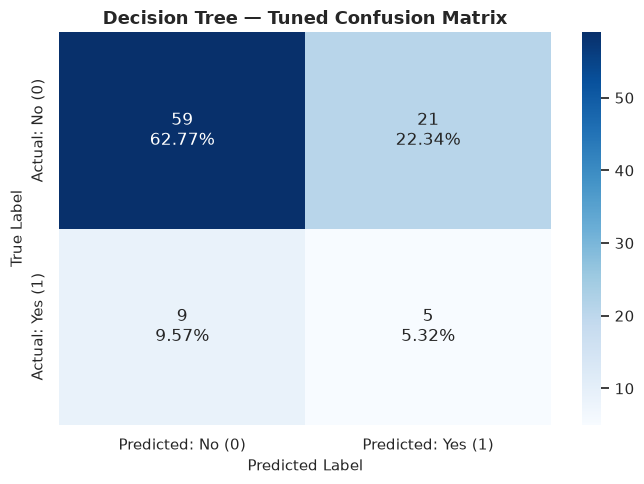


Classification Report:
                 precision    recall  f1-score   support

       Survived       0.87      0.74      0.80        80
Did not survive       0.19      0.36      0.25        14

       accuracy                           0.68        94
      macro avg       0.53      0.55      0.52        94
   weighted avg       0.77      0.68      0.72        94



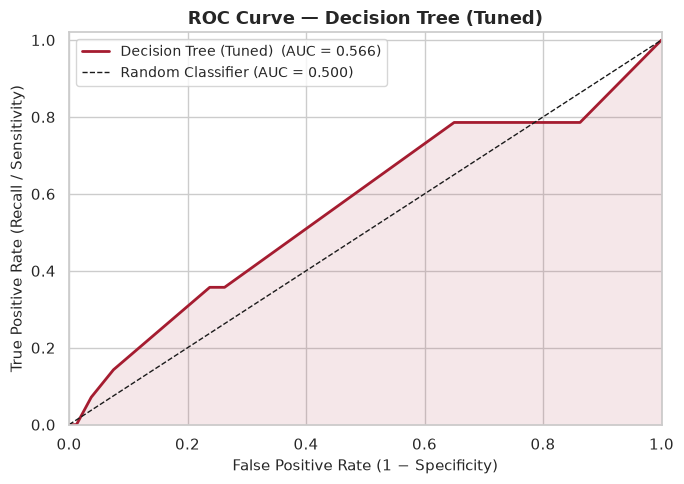

In [44]:
# @title ──────── Decision Tree - Tuned Model Evaluation ────────

print("Decision Tree — Tuned Model")
dt_tuned_scores = get_metrics_score(dt_tuned, X_train, X_test, y_train, y_test)

make_confusion_matrix(dt_tuned, X_test, y_test,
                      title="Decision Tree — Tuned Confusion Matrix")

dt_tuned_auc = plot_roc_curve(dt_tuned, X_test, y_test,
                              model_name="Decision Tree (Tuned)")


The recall of the tuned decision tree model has improved from the baseline, but still low, and the training metrics are still higher than the test metrics. The False Negative rate has improved from the baseline model, but is still higher than the previous models. The AUC value is 0.566, meaning this model is also only slightly better than a random classifier at predicting the outcome.

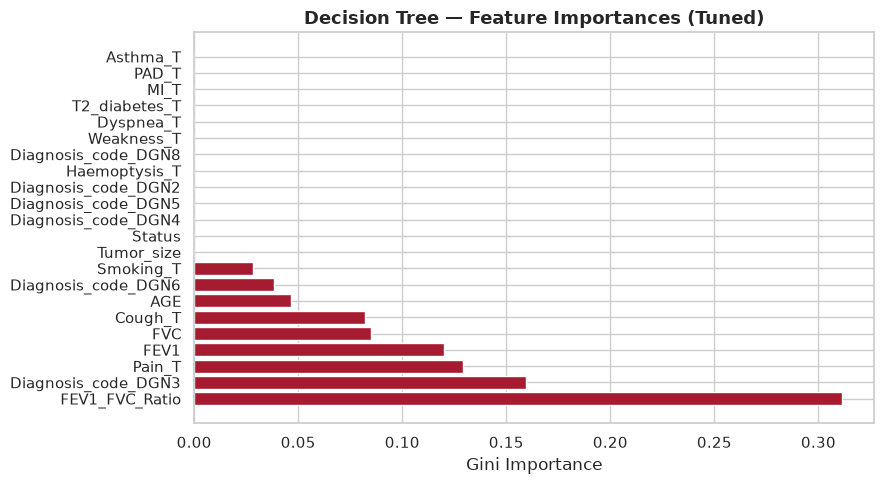

,Feature,Importance
5,FEV1_FVC_Ratio,0.3111
7,Diagnosis_code_DGN3,0.1597
12,Pain_T,0.1294
1,FEV1,0.1200
0,FVC,0.0848
15,Cough_T,0.0822
4,AGE,0.0466
10,Diagnosis_code_DGN6,0.0382
20,Smoking_T,0.0280
3,Tumor_size,0.0000


In [45]:
# @title ──────── Decision Tree - Feature Importance ────────

# =============================================================================
# Feature importance in a Decision Tree reflects the total reduction in
# impurity (gini) attributable to each feature across all splits.
# Gini impurity: represents the rate of mis-classification if decided by the class probability,
# which for this dataset is very unbalanced. (https://www.geeksforgeeks.org/machine-learning/gini-impurity-and-entropy-in-decision-tree-ml/)
# =============================================================================

dt_tuned_model = dt_tuned.named_steps['clf']
importances = dt_tuned_model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
}).sort_values('Importance', ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance_df['Feature'], importance_df['Importance'],
        color='#A51C30', edgecolor='white')
ax.set_title('Decision Tree — Feature Importances (Tuned)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Gini Importance')
plt.tight_layout()
plt.show()

display(importance_df.round(4))


The feature importance analysis for the decision tree model highlights the importance of the FEV1/FVC Ratio variable, while this was low for the logistic regression feature importance. Smoking was also high on the feature importance list for the logistic regression model, but is on the middle of the list for the decision tree feature importance.

### Interpretation of Tuned Decision Tree model

The Tuned Decision Tree model is better than the baseline Decision tree model, with the improved recall values for the test set. The overall ability of the model to predict the outcome also slightly improves, but when compared to the Logistic Regression and SVM models, is much worse by both metrics. Further comparison of the different models will continue below.


In [46]:
# @title ──────── Cross-Validation - All 3 Models and Tuned counterparts ────────

# =============================================================================
# Compute 5-fold stratified cross-validated recall for all trained models.
# Cross-validation is performed on the training set only.
# =============================================================================

cv_models = {
    'LR (Baseline)':  lr_pipeline,
    'LR (Tuned)':     lr_tuned,
    'SVM (Baseline)': svm_pipeline,
    'SVM (Tuned)':    svm_tuned,
    'DT (Baseline)':  dt_pipeline,
    'DT (Tuned)':     dt_tuned,
}

cv_results = {}
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train, y_train,
                             cv=cv, scoring='recall', n_jobs=-1)
    cv_results[name] = {
        'Mean CV Recall': scores.mean(),
        'Std CV Recall':  scores.std(),
        'Min':            scores.min(),
        'Max':            scores.max()
    }

cv_df = pd.DataFrame(cv_results).T.round(3)
cv_df = cv_df.sort_values('Mean CV Recall', ascending=False)

print("5-Fold Stratified Cross-Validation — Recall (Training Set)")
display(cv_df)


5-Fold Stratified Cross-Validation — Recall (Training Set)


,Mean CV Recall,Std CV Recall,Min,Max
SVM (Tuned),1.000,0.000,1.000,1.000
LR (Tuned),0.627,0.148,0.500,0.909
DT (Tuned),0.605,0.115,0.455,0.750
LR (Baseline),0.429,0.106,0.273,0.545
SVM (Baseline),0.321,0.091,0.182,0.455
DT (Baseline),0.052,0.067,0.000,0.167


### Interpretation of the Cross-Validation comparison of each model
As the Cross-validation was only performed on the training set, the Tuned SVM model appears to be the best performing model with the highest recall, but the recall value for the test set is more important when comparing model performance. A perfect value for the training set can also indicate that the model is overfit to the training set and less generalizable to other data. While the model with the lowest Mean CV Recall value, the baseline decision tree, also does have the lowest test set recall value, but the highest (technically perfect) training set recall value.

In [47]:
# @title ──────── Model Comparison Table ────────

all_models = {
    'Logistic Regression (Baseline)': (lr_pipeline,    lr_scores),
    'Logistic Regression (Tuned)':    (lr_tuned,       lr_tuned_scores),
    'SVM (Baseline)':                 (svm_pipeline,   svm_scores),
    'SVM (Tuned)':                    (svm_tuned,      svm_tuned_scores),
    'Decision Tree (Baseline)':       (dt_pipeline,    dt_scores),
    'Decision Tree (Tuned)':          (dt_tuned,       dt_tuned_scores),
}

comparison_rows = []
for model_name, (model_obj, scores) in all_models.items():
    comparison_rows.append({
        'Model':            model_name,
        'Train Accuracy':   scores[0],
        'Test Accuracy':    scores[1],
        'Train Recall':     scores[2],
        'Test Recall':      scores[3],
        'Train Precision':  scores[4],
        'Test Precision':   scores[5],
        'Train F1':         scores[6],
        'Test F1':          scores[7],
        'Test AUC-ROC':     scores[9],
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values('Test Recall', ascending=False)

print("Module 3 — Model Performance Comparison (Test Set)")
display(comparison_df.round(3))


Module 3 — Model Performance Comparison (Test Set)


,Model,Train Accuracy,Test Accuracy,Train Recall,Test Recall,Train Precision,Test Precision,Train F1,Test F1,Test AUC-ROC
3,SVM (Tuned),0.149,0.149,1.000,1.000,0.149,0.149,0.259,0.259,0.279
0,Logistic Regression (Baseline),0.697,0.681,0.696,0.714,0.287,0.278,0.406,0.400,0.757
1,Logistic Regression (Tuned),0.628,0.628,0.714,0.714,0.244,0.244,0.364,0.364,0.725
2,SVM (Baseline),0.814,0.723,0.768,0.500,0.430,0.269,0.551,0.350,0.652
5,Decision Tree (Tuned),0.747,0.681,0.589,0.357,0.314,0.192,0.410,0.250,0.566
4,Decision Tree (Baseline),1.000,0.734,1.000,0.143,1.000,0.133,1.000,0.138,0.490


While the previous comparison looked at the distribution of recall values from training set cross-validation for each model, this comparison looks at all the training and test set values for each model, providing the Test Recall values to compare side by side. As expected, the tuned SVM model has the highest test recall of 1, but both of the Logistic Regression models have the next highest Test recall value at 0.714. Interestingly, the Tuned Logistic Regression model, which was intended to be tuned for better recall, did not actually improve the test recall any higher. This table also highlights that the model with the highest Test Precision is also the Baseline Logistic Regression model, meaning it minimizes the number of false negatives and while the number of false positives are not minimized, it is the model that minimizes it the best.

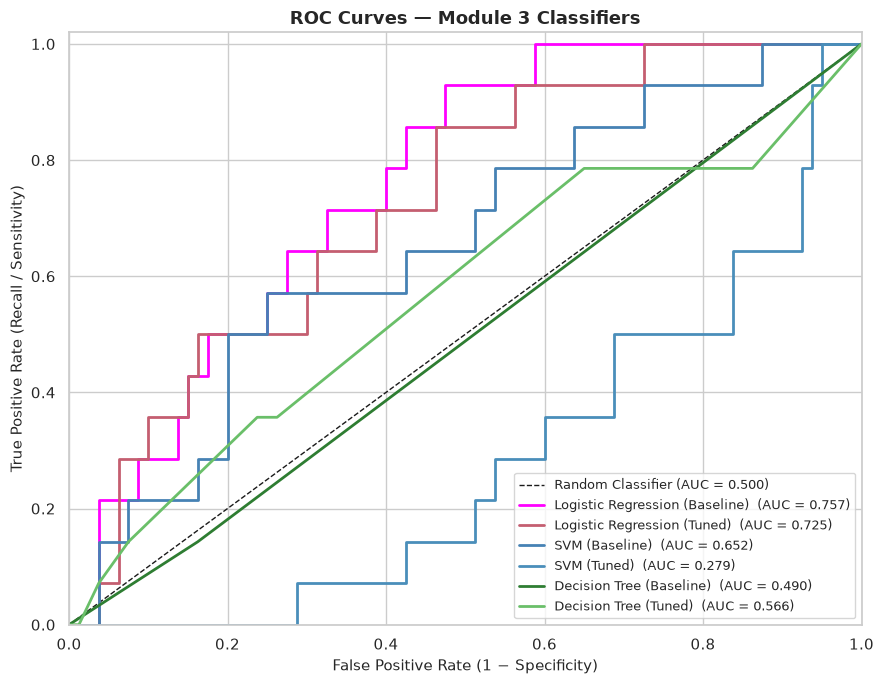

In [48]:
# @title ──────── Overlay of ROC-AUC Curves of All Models ────────


fig, ax = plt.subplots(figsize=(9, 7))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier (AUC = 0.500)')

colors = ['magenta', '#C45E70', 'steelblue', '#4A8EBA', '#2E7D32', '#6ABF69']

for (model_name, (model_obj, _)), color in zip(all_models.items(), colors):
    if hasattr(model_obj, 'predict_proba'):
        y_scores = model_obj.predict_proba(X_test)[:, 1]
    else:
        y_scores = model_obj.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_scores)
    auc = roc_auc_score(y_test, y_scores)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{model_name}  (AUC = {auc:.3f})')

ax.set_xlabel('False Positive Rate (1 − Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
ax.set_title('ROC Curves — Module 3 Classifiers', fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.show()


## Conclusion: Identifying the best of the six models based on the Recall and the ROC-AUC test metric values.
The best performing model for predicting the survival outcome 1 year post lung surgery is the Baseline Logistic Regression model. This model had the best Test Recall of 0.714 (tied with the tuned Logistic Regression model), and the highest AUC value of 0.757. This indicates that this model is the best at reducing the number of False Negatives, while also being the best of tested models for classifying this outcome. The Baseline Logistic Regression model not just has the highest Test Recall Score, it has the highest Test Precision and F1 scores, indicating it is the best at minimizing the number of False Positives without increasing the False Negative rate. For this dataset, the risk of not identifying patients at risk for not surviving the year after lung surgery is worse than over-identifying, and must be weighed more, the recall is the primary metric, but the other metrics are still important, which is why the Baseline Logistic Regression model is the best of these six models.




---


---


AI citations:

1.   Used Gemma 4 31b to figure out how to handle and unzip if the data comes from zip file. Prompts: "how to add unzip function to pathlib for loading data into google colab". "how does this library work"
```
import io
from pathlib import Path
```
"can you explain the second part of this code?"
```
import io
from pathlib import Path
import zipfile

# 1. Use pathlib to define the path
zip_path = Path('/content/data.zip')

# 2. Open the file and use io.BytesIO to handle the internal file streams
with zipfile.ZipFile(zip_path, 'r') as z:
    # Get the first file inside the zip
    first_file_name = z.namelist()[0]
    
    # Read the file content into a virtual memory file (io)
    with z.open(first_file_name) as f:
        content = io.BytesIO(f.read())
        # Now you can pass 'content' to a pandas dataframe or an image loader
```
"if the file in the zip is .arff, does the following code then make sense"
```
data, meta = arff.loadarff(file_data)
        df = pd.DataFrame(file_data)
```
```
TypeError: cannot use a string pattern on a bytes-like object
```
"The error occurs at data, meta = arff.loadarff line of code"



---





2.   Used Gemma 4 31b on 18OCT2026 to figure out how to adapt the created function for annotating barplots with the percentages and to use for looping through all categorical columns.
Prompts: "I’m looping through columns, how do I set the indexes for the specific number of categories in each column, instead of them all having 6"
```
ax.set_xticks([0, 1, 2, 3, 4, 5])
```
"can you make a grid of charts using sns.countplot"

```
for p in ax.patches:
```
"can you explain this code?"

"can this code be used in the above numpy array?"

```
cat_columns = df.select_dtypes('str')
```
"how do I turn this into a list of column names"


---







*   To rename multiple columns at once (https://www.geeksforgeeks.org/python/how-to-rename-multiple-column-headers-in-a-pandas-dataframe/)



